# Analyse Avancée des Résultats Électoraux : Présidentielle 2022 T1
> Exploration complète par bureau de vote, commune, département et candidat

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.insert(0, '/content/drive/MyDrive/Stage')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import geopandas as gpd
import warnings
warnings.filterwarnings('ignore')

# Style global
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3
})

CANDIDATS_COLORS = {
    'MACRON_Emmanuel':     '#FFD700',
    'LE PEN_Marine':       '#1E3A8A',
    'MÉLENCHON_Jean-Luc': '#E53E3E',
    'ZEMMOUR_Éric':        '#1A202C',
    'PÉCRESSE_Valérie':    '#3182CE',
    'JADOT_Yannick':       '#38A169',
    'LASSALLE_Jean':       '#D69E2E',
    'ROUSSEL_Fabien':      '#C53030',
    'HIDALGO_Anne':        '#ED8936',
    'DUPONT-AIGNAN_Nicolas':'#718096',
    'POUTOU_Philippe':     '#9B2C2C',
    'ARTHAUD_Nathalie':    '#E53E3E',
}
print("Setup OK")

Mounted at /content/drive
Setup OK


## Chargement et structuration des données

In [2]:
df = pd.read_excel("/content/drive/MyDrive/Stage/1er tour/resultats-par-niveau-burvot-t1-france-entiere.xlsx")

df.head()

,Code du département,Libellé du département,Code de la circonscription,Libellé de la circonscription,Code de la commune,Libellé de la commune,Code du b.vote,Inscrits,Abstentions,% Abs/Ins,...,Unnamed: 95,Unnamed: 96,Unnamed: 97,Unnamed: 98,Unnamed: 99,Unnamed: 100,Unnamed: 101,Unnamed: 102,Unnamed: 103,Unnamed: 104
0,01,Ain,4,4ème circonscription,1,L'Abergement-Clémenciat,0001,645,108,16.74,...,3,0.47,0.58,12,M,DUPONT-AIGNAN,Nicolas,21,3.26,4.04
1,01,Ain,5,5ème circonscription,2,L'Abergement-de-Varey,0001,213,38,17.84,...,3,1.41,1.75,12,M,DUPONT-AIGNAN,Nicolas,0,0.00,0.00
2,01,Ain,5,5ème circonscription,4,Ambérieu-en-Bugey,0001,1129,266,23.56,...,8,0.71,0.95,12,M,DUPONT-AIGNAN,Nicolas,13,1.15,1.55
3,01,Ain,5,5ème circonscription,4,Ambérieu-en-Bugey,0002,1128,265,23.49,...,4,0.35,0.48,12,M,DUPONT-AIGNAN,Nicolas,20,1.77,2.38
4,01,Ain,5,5ème circonscription,4,Ambérieu-en-Bugey,0003,1213,246,20.28,...,3,0.25,0.32,12,M,DUPONT-AIGNAN,Nicolas,19,1.57,2.00


In [3]:
print(f"Dimensions brutes : {df.shape}")
# ── ID bureau de vote
df["id_bv"] = (
    df["Code du département"].astype(str).str.zfill(2) + "_" +
    df["Code de la commune"].astype(str).str.zfill(3) + "_" +
    df["Code du b.vote"].astype(str).str.zfill(4)
)

cols_fix = [
    "Code du département","Libellé du département",
    "Code de la circonscription","Libellé de la circonscription",
    "Code de la commune","Libellé de la commune",
    "Code du b.vote","id_bv",
    "Inscrits","Abstentions","% Abs/Ins",
    "Votants","% Vot/Ins","Blancs","% Blancs/Ins","% Blancs/Vot",
    "Nuls","% Nuls/Ins","% Nuls/Vot",
    "Exprimés","% Exp/Ins","% Exp/Vot"
]
df_fix = df[cols_fix].copy()

# ── Format long : une ligne par (bureau, candidat)
candidats = []
start = df.columns.get_loc("N°Panneau")
for i in range(start, start + 12*7, 7):
    bloc = df.iloc[:, i:i+7].copy()
    bloc.columns = ["panneau","sexe","nom","prenom","voix","pct_ins","pct_exp"]
    candidats.append(pd.concat([df_fix, bloc], axis=1))
df_long = pd.concat(candidats, ignore_index=True)
df_long["candidat"] = df_long["nom"] + "_" + df_long["prenom"]

# ── Format large : une ligne par bureau
pivot = df_long.pivot_table(
    index="id_bv", columns="candidat",
    values="pct_exp", aggfunc="sum"
).fillna(0).reset_index()

meta_cols = ["id_bv","Code du département","Libellé du département",
             "Code de la commune","Libellé de la commune",
             "Inscrits","Abstentions","% Abs/Ins",
             "Votants","% Vot/Ins","Exprimés","% Exp/Vot"]
meta = df_fix.drop_duplicates("id_bv")[meta_cols]
final_df = pivot.merge(meta, on="id_bv")

CANDS = [c for c in pivot.columns if c != "id_bv"]
n_brut = len(final_df)
print(f"✓ {len(final_df):,} bureaux de vote")
print(f"✓ {len(CANDS)} candidats : {CANDS}")
print(f"✓ Format long : {df_long.shape}")
final_df.head()

Dimensions brutes : (69682, 105)
✓ 69,682 bureaux de vote
✓ 12 candidats : ['ARTHAUD_Nathalie', 'DUPONT-AIGNAN_Nicolas', 'HIDALGO_Anne', 'JADOT_Yannick', 'LASSALLE_Jean', 'LE PEN_Marine', 'MACRON_Emmanuel', 'MÉLENCHON_Jean-Luc', 'POUTOU_Philippe', 'PÉCRESSE_Valérie', 'ROUSSEL_Fabien', 'ZEMMOUR_Éric']
✓ Format long : (836184, 30)


,id_bv,ARTHAUD_Nathalie,DUPONT-AIGNAN_Nicolas,HIDALGO_Anne,JADOT_Yannick,LASSALLE_Jean,LE PEN_Marine,MACRON_Emmanuel,MÉLENCHON_Jean-Luc,POUTOU_Philippe,...,Libellé du département,Code de la commune,Libellé de la commune,Inscrits,Abstentions,% Abs/Ins,Votants,% Vot/Ins,Exprimés,% Exp/Vot
0,01_001_0001,0.58,4.04,0.96,5.77,3.46,28.65,28.85,12.69,0.58,...,Ain,1,L'Abergement-Clémenciat,645,108,16.74,537,83.26,520,96.83
1,01_002_0001,1.17,0.00,1.75,5.85,5.85,13.45,29.24,23.98,1.75,...,Ain,2,L'Abergement-de-Varey,213,38,17.84,175,82.16,171,97.71
2,01_004_0001,0.48,1.55,1.79,2.98,2.86,28.21,18.93,25.71,0.95,...,Ain,4,Ambérieu-en-Bugey,1129,266,23.56,863,76.44,840,97.33
3,01_004_0002,0.71,2.38,2.26,5.46,2.26,24.94,23.87,23.04,0.48,...,Ain,4,Ambérieu-en-Bugey,1128,265,23.49,863,76.51,842,97.57
4,01_004_0003,0.84,2.00,1.69,6.85,2.95,23.92,24.13,23.92,0.32,...,Ain,4,Ambérieu-en-Bugey,1213,246,20.28,967,79.72,949,98.14


In [4]:
# Mapping DOM : codes Z → codes numériques pour harmoniser avec les Voronoï
DOM_MAPPING = {
    "ZA": "971",  # Guadeloupe
    "ZB": "972",  # Martinique
    "ZC": "973",  # Guyane
    "ZD": "974",  # La Réunion
    "ZS": "975",   #Saint-Pierre-et-Miquelon
    "ZM": "976",  # Mayotte
}

# Territoires à exclure (pas de données INSEE, pas de Voronoï)
EXCLURE = {"ZN", "ZP", "ZW", "ZX", "ZZ"}

# Étape 1 — Exclure les territoires sans Voronoï
mask_exclure = final_df["Code du département"].astype(str).isin(EXCLURE)
print(f"Bureaux exclus : {mask_exclure.sum():,}")
print(final_df[mask_exclure].groupby("Libellé du département")["id_bv"].count())

final_df = final_df[~mask_exclure].copy()

# Étape 2 — Harmoniser les codes DOM (ZA→971, ZB→972...)
final_df["Code du département"] = (
    final_df["Code du département"]
    .astype(str)
    .replace(DOM_MAPPING)
)

# Étape 3 — Reconstruire id_bv cohérent avec les Voronoï pour les DOM
# Avant : id_bv = "ZA_001_0001" → Après : "971_001_0001"
for z_code, num_code in DOM_MAPPING.items():
    mask = final_df["id_bv"].str.startswith(z_code)
    final_df.loc[mask, "id_bv"] = (
        final_df.loc[mask, "id_bv"].str.replace(z_code, num_code, n=1)
    )

# Vérification finale
print(f"\nBureaux conservés : {len(final_df):,}")
print("\nDépartements présents après nettoyage :")
print(final_df["Code du département"].unique())



Bureaux exclus : 784
Libellé du département
Français établis hors de France    210
Nouvelle-Calédonie                 297
Polynésie française                250
Saint-Martin/Saint-Barthélemy       26
Wallis et Futuna                     1
Name: id_bv, dtype: int64

Bureaux conservés : 68,898

Départements présents après nettoyage :
['01' '02' '03' '04' '05' '06' '07' '08' '09' '10' '11' '12' '13' '14'
 '15' '16' '17' '18' '19' '21' '22' '23' '24' '25' '26' '27' '28' '29'
 '2A' '2B' '30' '31' '32' '33' '34' '35' '36' '37' '38' '39' '40' '41'
 '42' '43' '44' '45' '46' '47' '48' '49' '50' '51' '52' '53' '54' '55'
 '56' '57' '58' '59' '60' '61' '62' '63' '64' '65' '66' '67' '68' '69'
 '70' '71' '72' '73' '74' '75' '76' '77' '78' '79' '80' '81' '82' '83'
 '84' '85' '86' '87' '88' '89' '90' '91' '92' '93' '94' '95' '971' '972'
 '973' '974' '976' '975']


In [5]:
# ── FILTRAGE DES BUREAUX NON FIABLES ──────────────────────────
n_avant = len(final_df)
print(f"Avant filtrage : {n_avant:,} bureaux")

# Distribution pour choisir le seuil
for s in [1, 5, 10, 20, 50]:
    n = (final_df["Exprimés"] < s).sum()
    print(f"  Exprimés < {s:>3} : {n:>5} bureaux ({n/n_avant*100:.2f}%)")

# Appliquer le filtre
final_df = final_df[
    (final_df["Exprimés"] >= 10) &
    (final_df["Inscrits"]  >  0) &
    (final_df["% Vot/Ins"] >  0)
].copy()

n_apres = len(final_df)
print(f"\nAprès filtrage  : {n_apres:,} bureaux")
print(f"Retirés         : {n_avant - n_apres:,} bureaux")
print(f"\nMax Macron      : {final_df['MACRON_Emmanuel'].max():.1f}%")
print(f"Max Le Pen      : {final_df['LE PEN_Marine'].max():.1f}%")
print(f"Max Mélenchon   : {final_df['MÉLENCHON_Jean-Luc'].max():.1f}%")

Avant filtrage : 68,898 bureaux
  Exprimés <   1 :    59 bureaux (0.09%)
  Exprimés <   5 :   104 bureaux (0.15%)
  Exprimés <  10 :   128 bureaux (0.19%)
  Exprimés <  20 :   265 bureaux (0.38%)
  Exprimés <  50 :  2129 bureaux (3.09%)

Après filtrage  : 68,770 bureaux
Retirés         : 128 bureaux

Max Macron      : 77.5%
Max Le Pen      : 78.0%
Max Mélenchon   : 91.0%


## Résultats nationaux : Vue d'ensemble

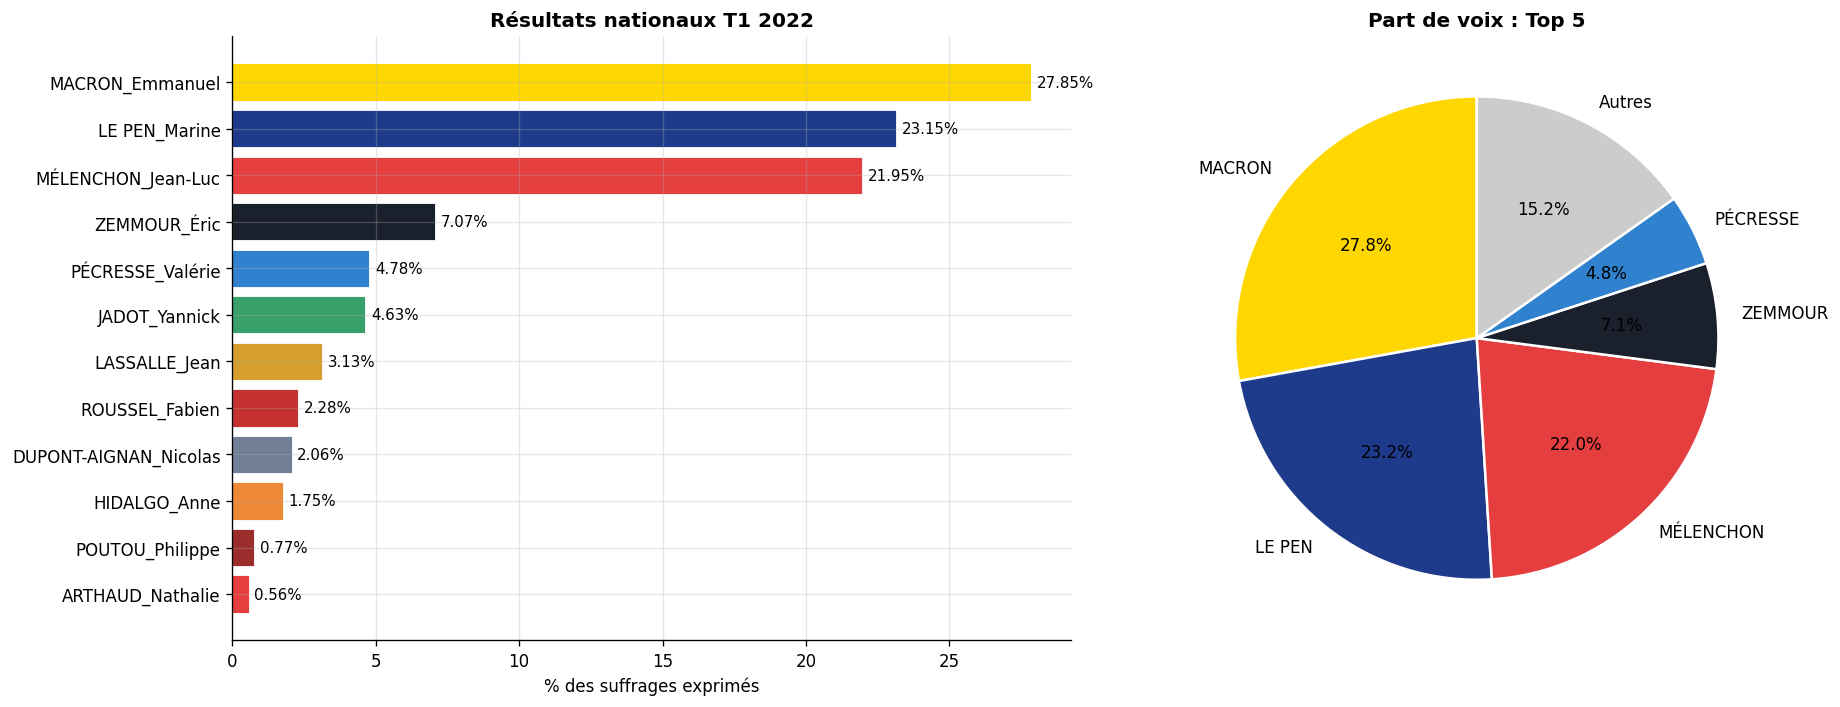

             Candidat  Voix totales  % exprimés
      MACRON_Emmanuel       9783058       27.85
        LE PEN_Marine       8133828       23.15
   MÉLENCHON_Jean-Luc       7712520       21.95
         ZEMMOUR_Éric       2485226        7.07
     PÉCRESSE_Valérie       1679001        4.78
        JADOT_Yannick       1627853        4.63
        LASSALLE_Jean       1101387        3.13
       ROUSSEL_Fabien        802422        2.28
DUPONT-AIGNAN_Nicolas        725176        2.06
         HIDALGO_Anne        616478        1.75
      POUTOU_Philippe        268904        0.77
     ARTHAUD_Nathalie        197094        0.56


In [6]:
# Résultats nationaux pondérés par les exprimés
resultats_nat = {}
for c in CANDS:
    voix_tot = (df_long[df_long['candidat']==c]['voix'].sum())
    resultats_nat[c] = voix_tot

total_voix = sum(resultats_nat.values())
pct_nat = {c: v/total_voix*100 for c,v in resultats_nat.items()}
pct_sorted = dict(sorted(pct_nat.items(), key=lambda x: -x[1]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Barplot
colors = [CANDIDATS_COLORS.get(c, '#888') for c in pct_sorted]
bars = axes[0].barh(list(pct_sorted.keys()), list(pct_sorted.values()),
                    color=colors, edgecolor='white', linewidth=0.5)
axes[0].set_xlabel("% des suffrages exprimés")
axes[0].set_title("Résultats nationaux T1 2022", fontweight='bold')
for bar, val in zip(bars, pct_sorted.values()):
    axes[0].text(val + 0.2, bar.get_y() + bar.get_height()/2,
                 f'{val:.2f}%', va='center', fontsize=9)
axes[0].invert_yaxis()

# Camembert top 5
top5 = dict(list(pct_sorted.items())[:5])
autres = 100 - sum(top5.values())
top5['Autres'] = autres
colors_pie = [CANDIDATS_COLORS.get(c, '#ccc') for c in top5]
axes[1].pie(top5.values(), labels=[c.split('_')[0] for c in top5],
            colors=colors_pie, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':1.5})
axes[1].set_title("Part de voix : Top 5", fontweight='bold')

plt.tight_layout()
plt.show()

# Tableau récap
df_nat = pd.DataFrame({'Candidat': list(pct_sorted.keys()),
                        'Voix totales': [resultats_nat[c] for c in pct_sorted],
                        '% exprimés': [round(pct_sorted[c],2) for c in pct_sorted]})
print(df_nat.to_string(index=False))

## 3. Analyse de la participation

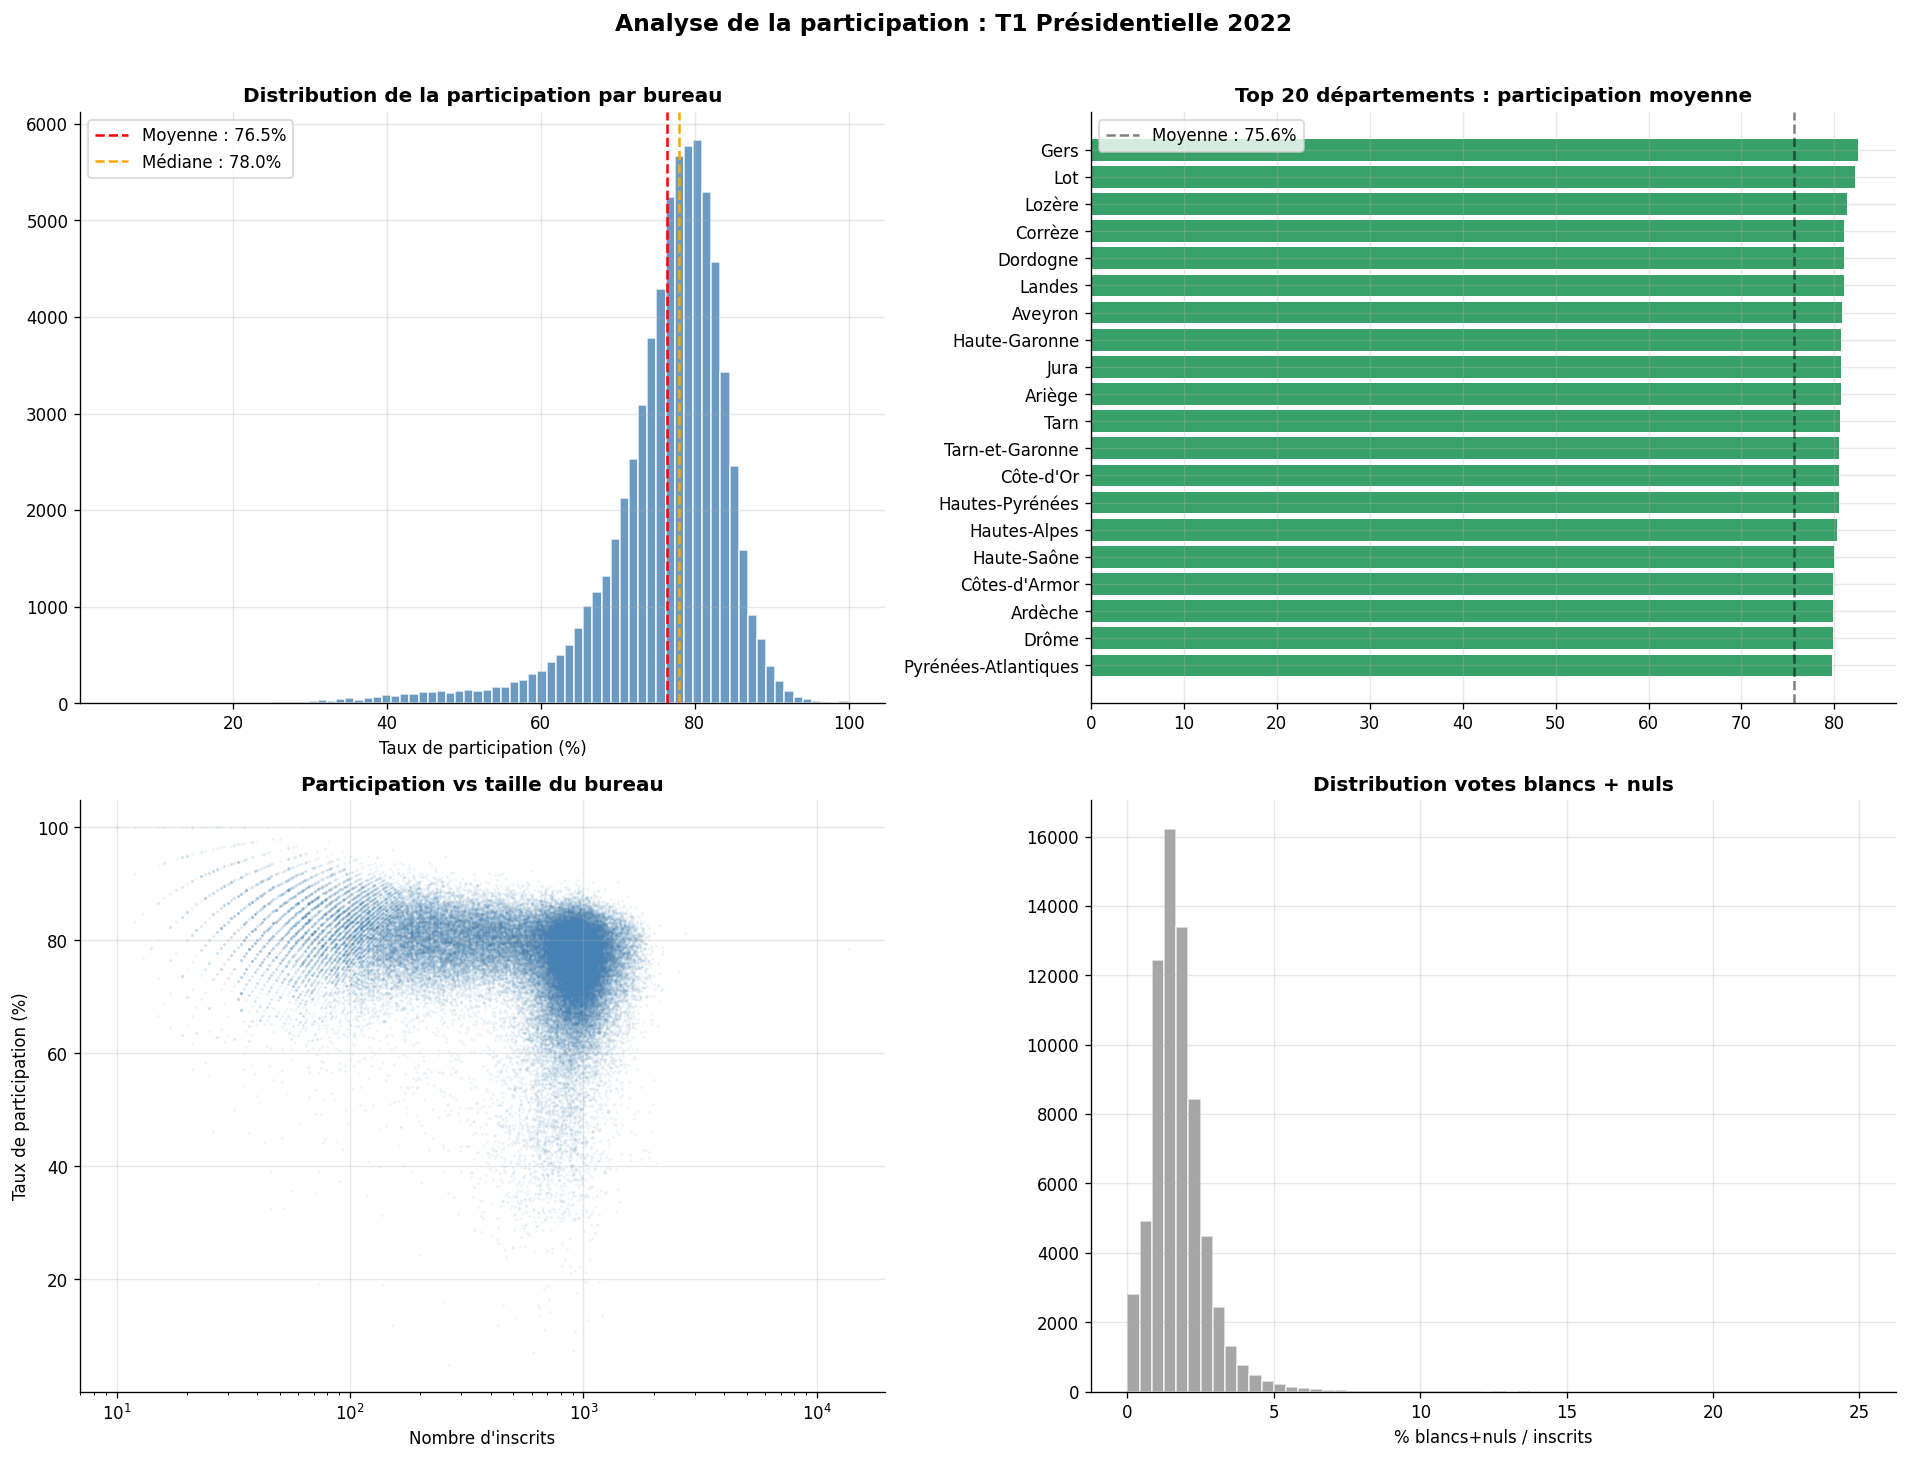


── Top 5 départements les plus mobilisés ──
Libellé du département
Dordogne    81.017631
Corrèze     81.033055
Lozère      81.387500
Lot         82.210551
Gers        82.496680

── Top 5 départements les moins mobilisés ──
Libellé du département
Guyane                      35.883459
Mayotte                     40.822363
Martinique                  42.521566
Guadeloupe                  44.636881
Saint-Pierre-et-Miquelon    53.535000


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Distribution participation par bureau
axes[0,0].hist(final_df['% Vot/Ins'], bins=80, color='steelblue', edgecolor='white', alpha=0.8)
axes[0,0].axvline(final_df['% Vot/Ins'].mean(), color='red', linestyle='--',
                   label=f"Moyenne : {final_df['% Vot/Ins'].mean():.1f}%")
axes[0,0].axvline(final_df['% Vot/Ins'].median(), color='orange', linestyle='--',
                   label=f"Médiane : {final_df['% Vot/Ins'].median():.1f}%")
axes[0,0].set_xlabel("Taux de participation (%)")
axes[0,0].set_title("Distribution de la participation par bureau", fontweight='bold')
axes[0,0].legend()

# Participation par département (boxplot top 20)
dep_part = final_df.groupby("Libellé du département")["% Vot/Ins"].mean().sort_values()
colors_dep = ['#E53E3E' if v < dep_part.mean() else '#38A169' for v in dep_part.values]
axes[0,1].barh(dep_part.index[-20:], dep_part.values[-20:],
               color=[c for c in colors_dep[-20:]])
axes[0,1].axvline(dep_part.mean(), color='black', linestyle='--', alpha=0.5,
                   label=f'Moyenne : {dep_part.mean():.1f}%')
axes[0,1].set_title("Top 20 départements : participation moyenne", fontweight='bold')
axes[0,1].legend()

# Participation vs taille du bureau
axes[1,0].scatter(final_df['Inscrits'], final_df['% Vot/Ins'],
                   alpha=0.05, s=1, color='steelblue')
axes[1,0].set_xlabel("Nombre d'inscrits")
axes[1,0].set_ylabel("Taux de participation (%)")
axes[1,0].set_title("Participation vs taille du bureau", fontweight='bold')
axes[1,0].set_xscale('log')

# Taux de blancs/nuls
axes[1,1].hist(final_df['% Vot/Ins'] - final_df['% Exp/Vot'] * final_df['% Vot/Ins'] / 100,
               bins=60, color='gray', alpha=0.7, edgecolor='white')
axes[1,1].set_xlabel("% blancs+nuls / inscrits")
axes[1,1].set_title("Distribution votes blancs + nuls", fontweight='bold')

plt.suptitle("Analyse de la participation : T1 Présidentielle 2022",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Stats par département
print("\n── Top 5 départements les plus mobilisés ──")
print(dep_part.tail(5).to_string())
print("\n── Top 5 départements les moins mobilisés ──")
print(dep_part.head(5).to_string())

## Analyse par candidat — Distributions et géographie

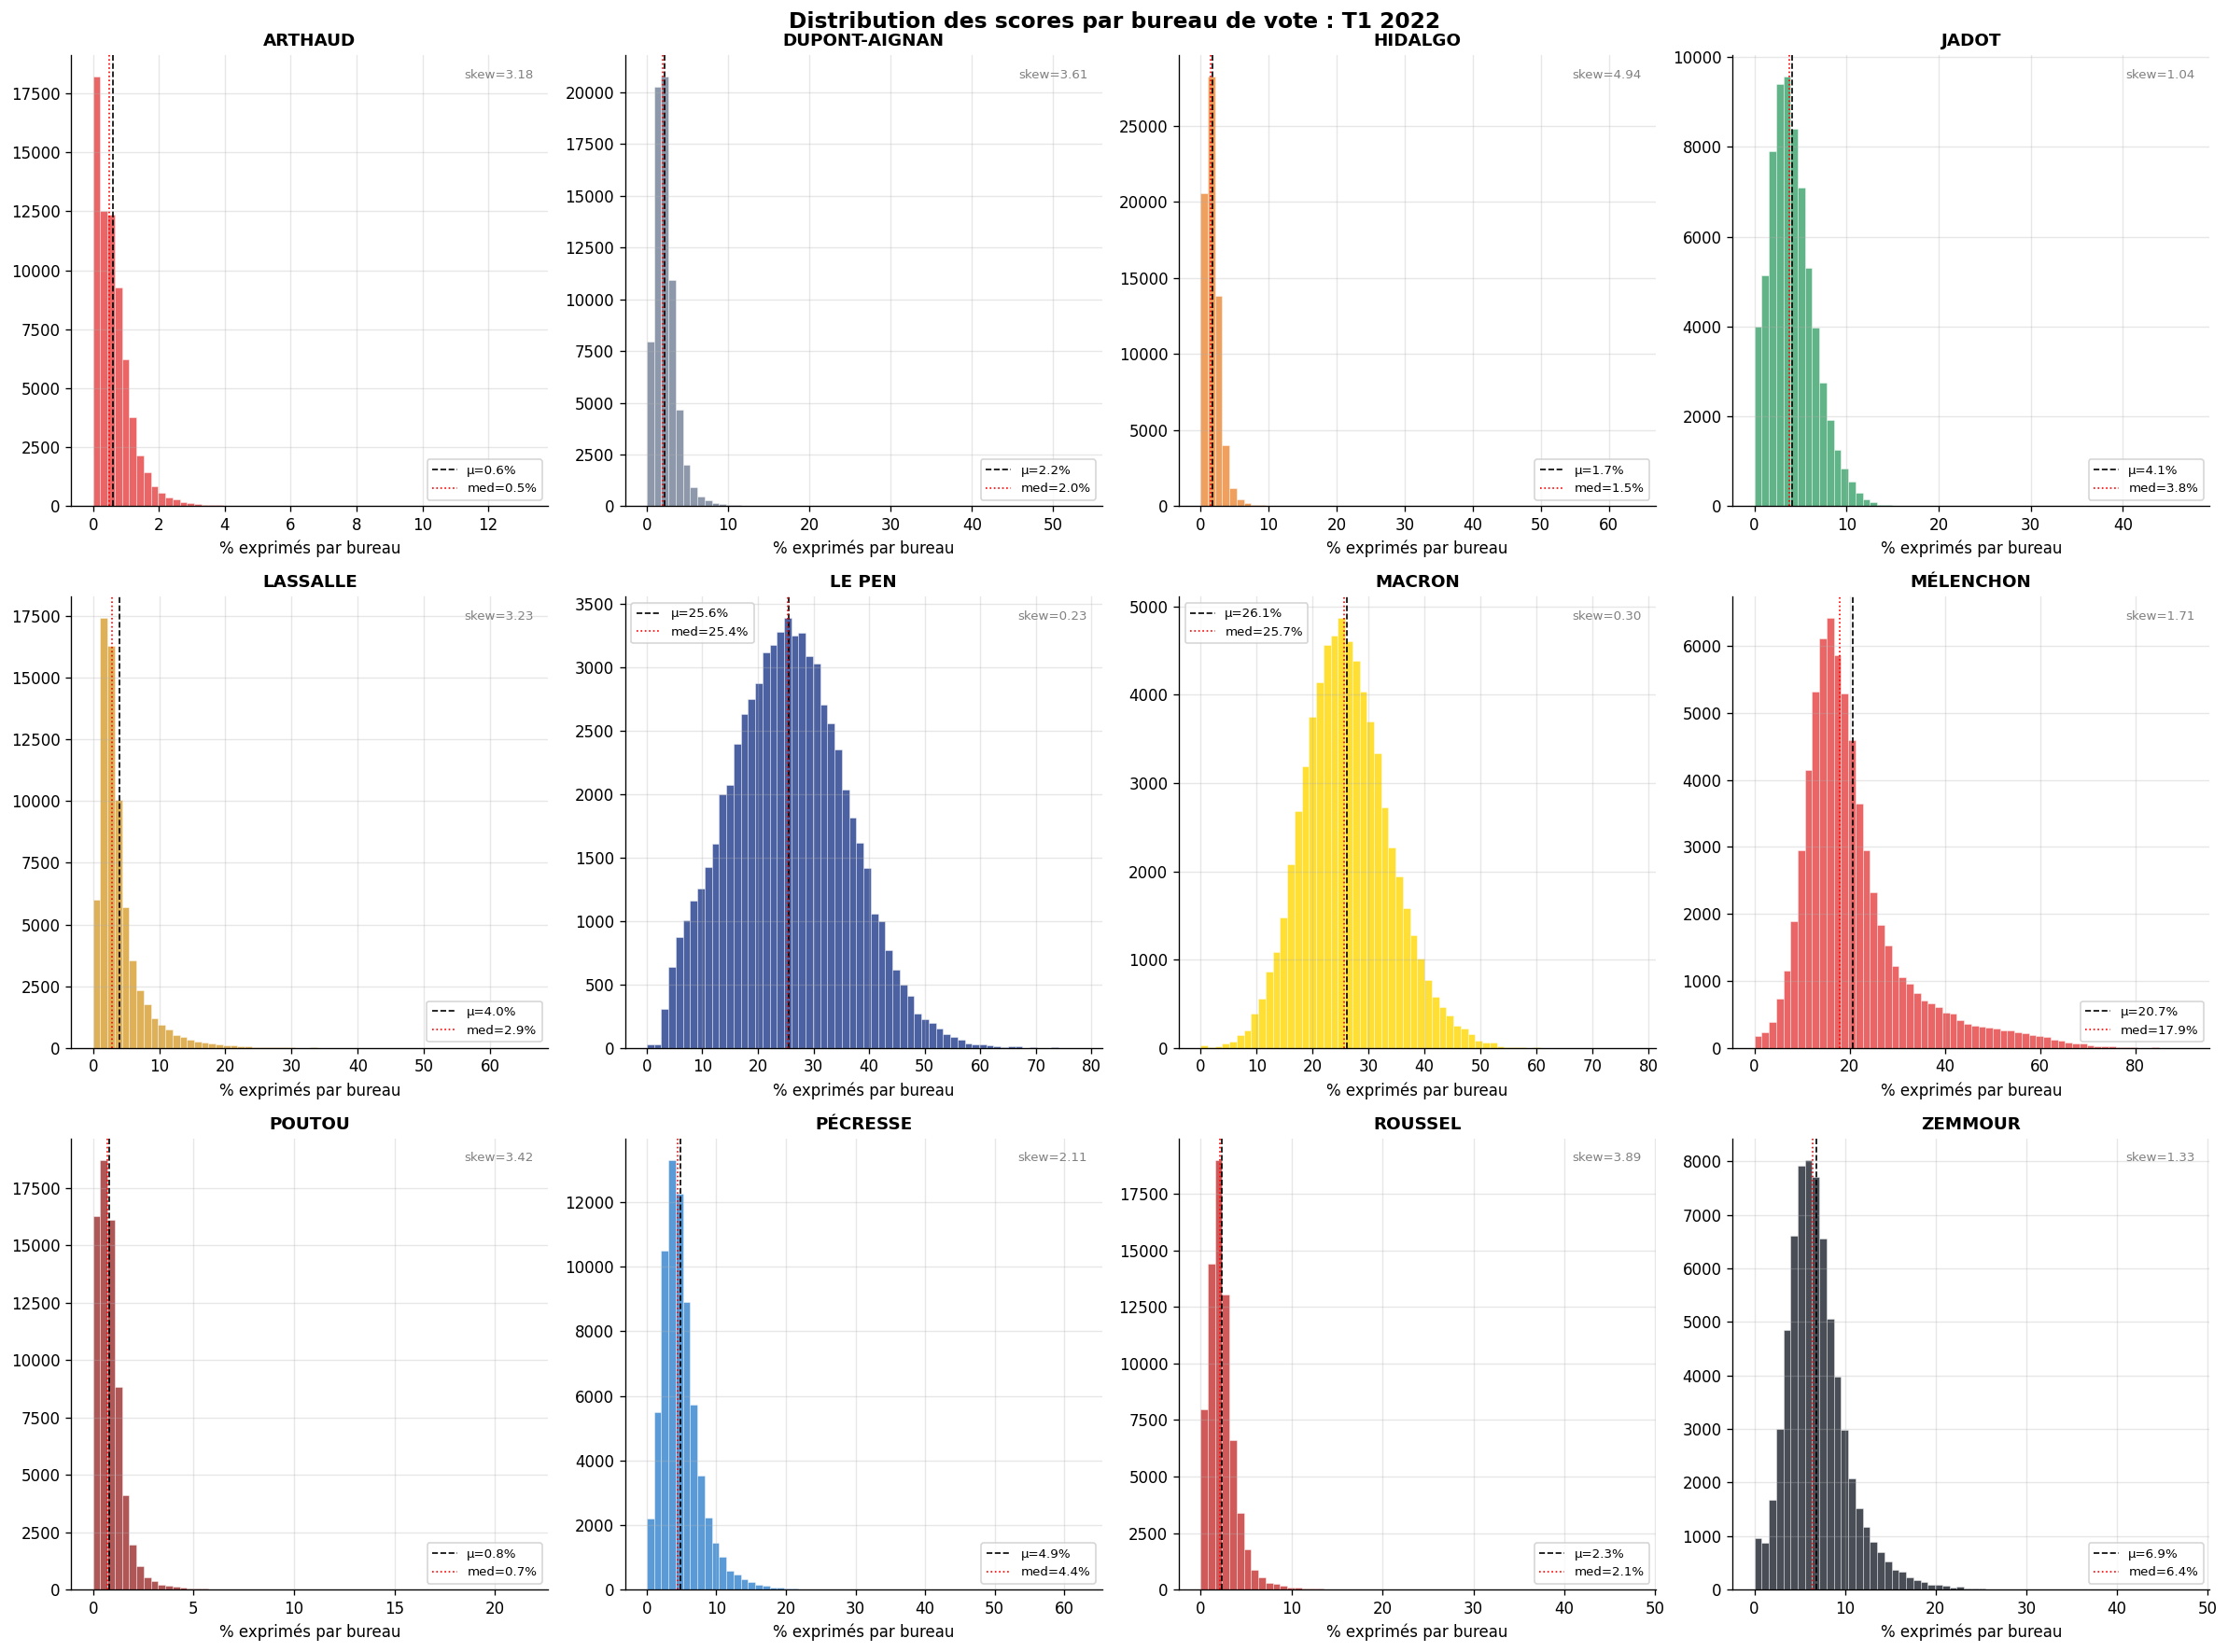

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for idx, cand in enumerate(CANDS):
    ax = axes[idx]
    data = final_df[cand]
    color = CANDIDATS_COLORS.get(cand, '#888')

    ax.hist(data, bins=60, color=color, alpha=0.8, edgecolor='white', linewidth=0.3)
    ax.axvline(data.mean(), color='black', linestyle='--', linewidth=1,
               label=f'μ={data.mean():.1f}%')
    ax.axvline(data.median(), color='red', linestyle=':', linewidth=1,
               label=f'med={data.median():.1f}%')

    nom_court = cand.split('_')[0]
    ax.set_title(f"{nom_court}", fontweight='bold', fontsize=11)
    ax.set_xlabel("% exprimés par bureau")
    ax.legend(fontsize=8)

    # Annotation skewness
    skew = data.skew()
    ax.text(0.97, 0.97, f'skew={skew:.2f}', transform=ax.transAxes,
            ha='right', va='top', fontsize=8, color='gray')

plt.suptitle("Distribution des scores par bureau de vote : T1 2022",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [9]:
# Scores max, min, variance par candidat
stats_cands = []
for c in CANDS:
    stats_cands.append({
        'Candidat': c.split('_')[0],
        'Moyenne (%)': round(final_df[c].mean(), 2),
        'Médiane (%)': round(final_df[c].median(), 2),
        'Écart-type': round(final_df[c].std(), 2),
        'Max bureau (%)': round(final_df[c].max(), 2),
        'Min bureau (%)': round(final_df[c].min(), 2),
        'Bureaux > 50%': (final_df[c] > 50).sum(),
    })
df_stats = pd.DataFrame(stats_cands).sort_values('Moyenne (%)', ascending=False)
print(df_stats.to_string(index=False))

     Candidat  Moyenne (%)  Médiane (%)  Écart-type  Max bureau (%)  Min bureau (%)  Bureaux > 50%
       MACRON        26.14        25.70        7.71           77.46             0.0            190
       LE PEN        25.57        25.37       10.47           78.00             0.0            862
    MÉLENCHON        20.73        17.93       11.30           91.03             0.0           2409
      ZEMMOUR         6.89         6.43        3.39           47.83             0.0              0
     PÉCRESSE         4.88         4.38        2.90           62.32             0.0              2
        JADOT         4.11         3.79        2.46           47.06             0.0              0
     LASSALLE         3.95         2.87        3.71           65.49             0.0              3
      ROUSSEL         2.35         2.08        1.75           47.67             0.0              0
DUPONT-AIGNAN         2.24         2.01        1.49           53.33             0.0              2
      HIDA

## Analyse par département

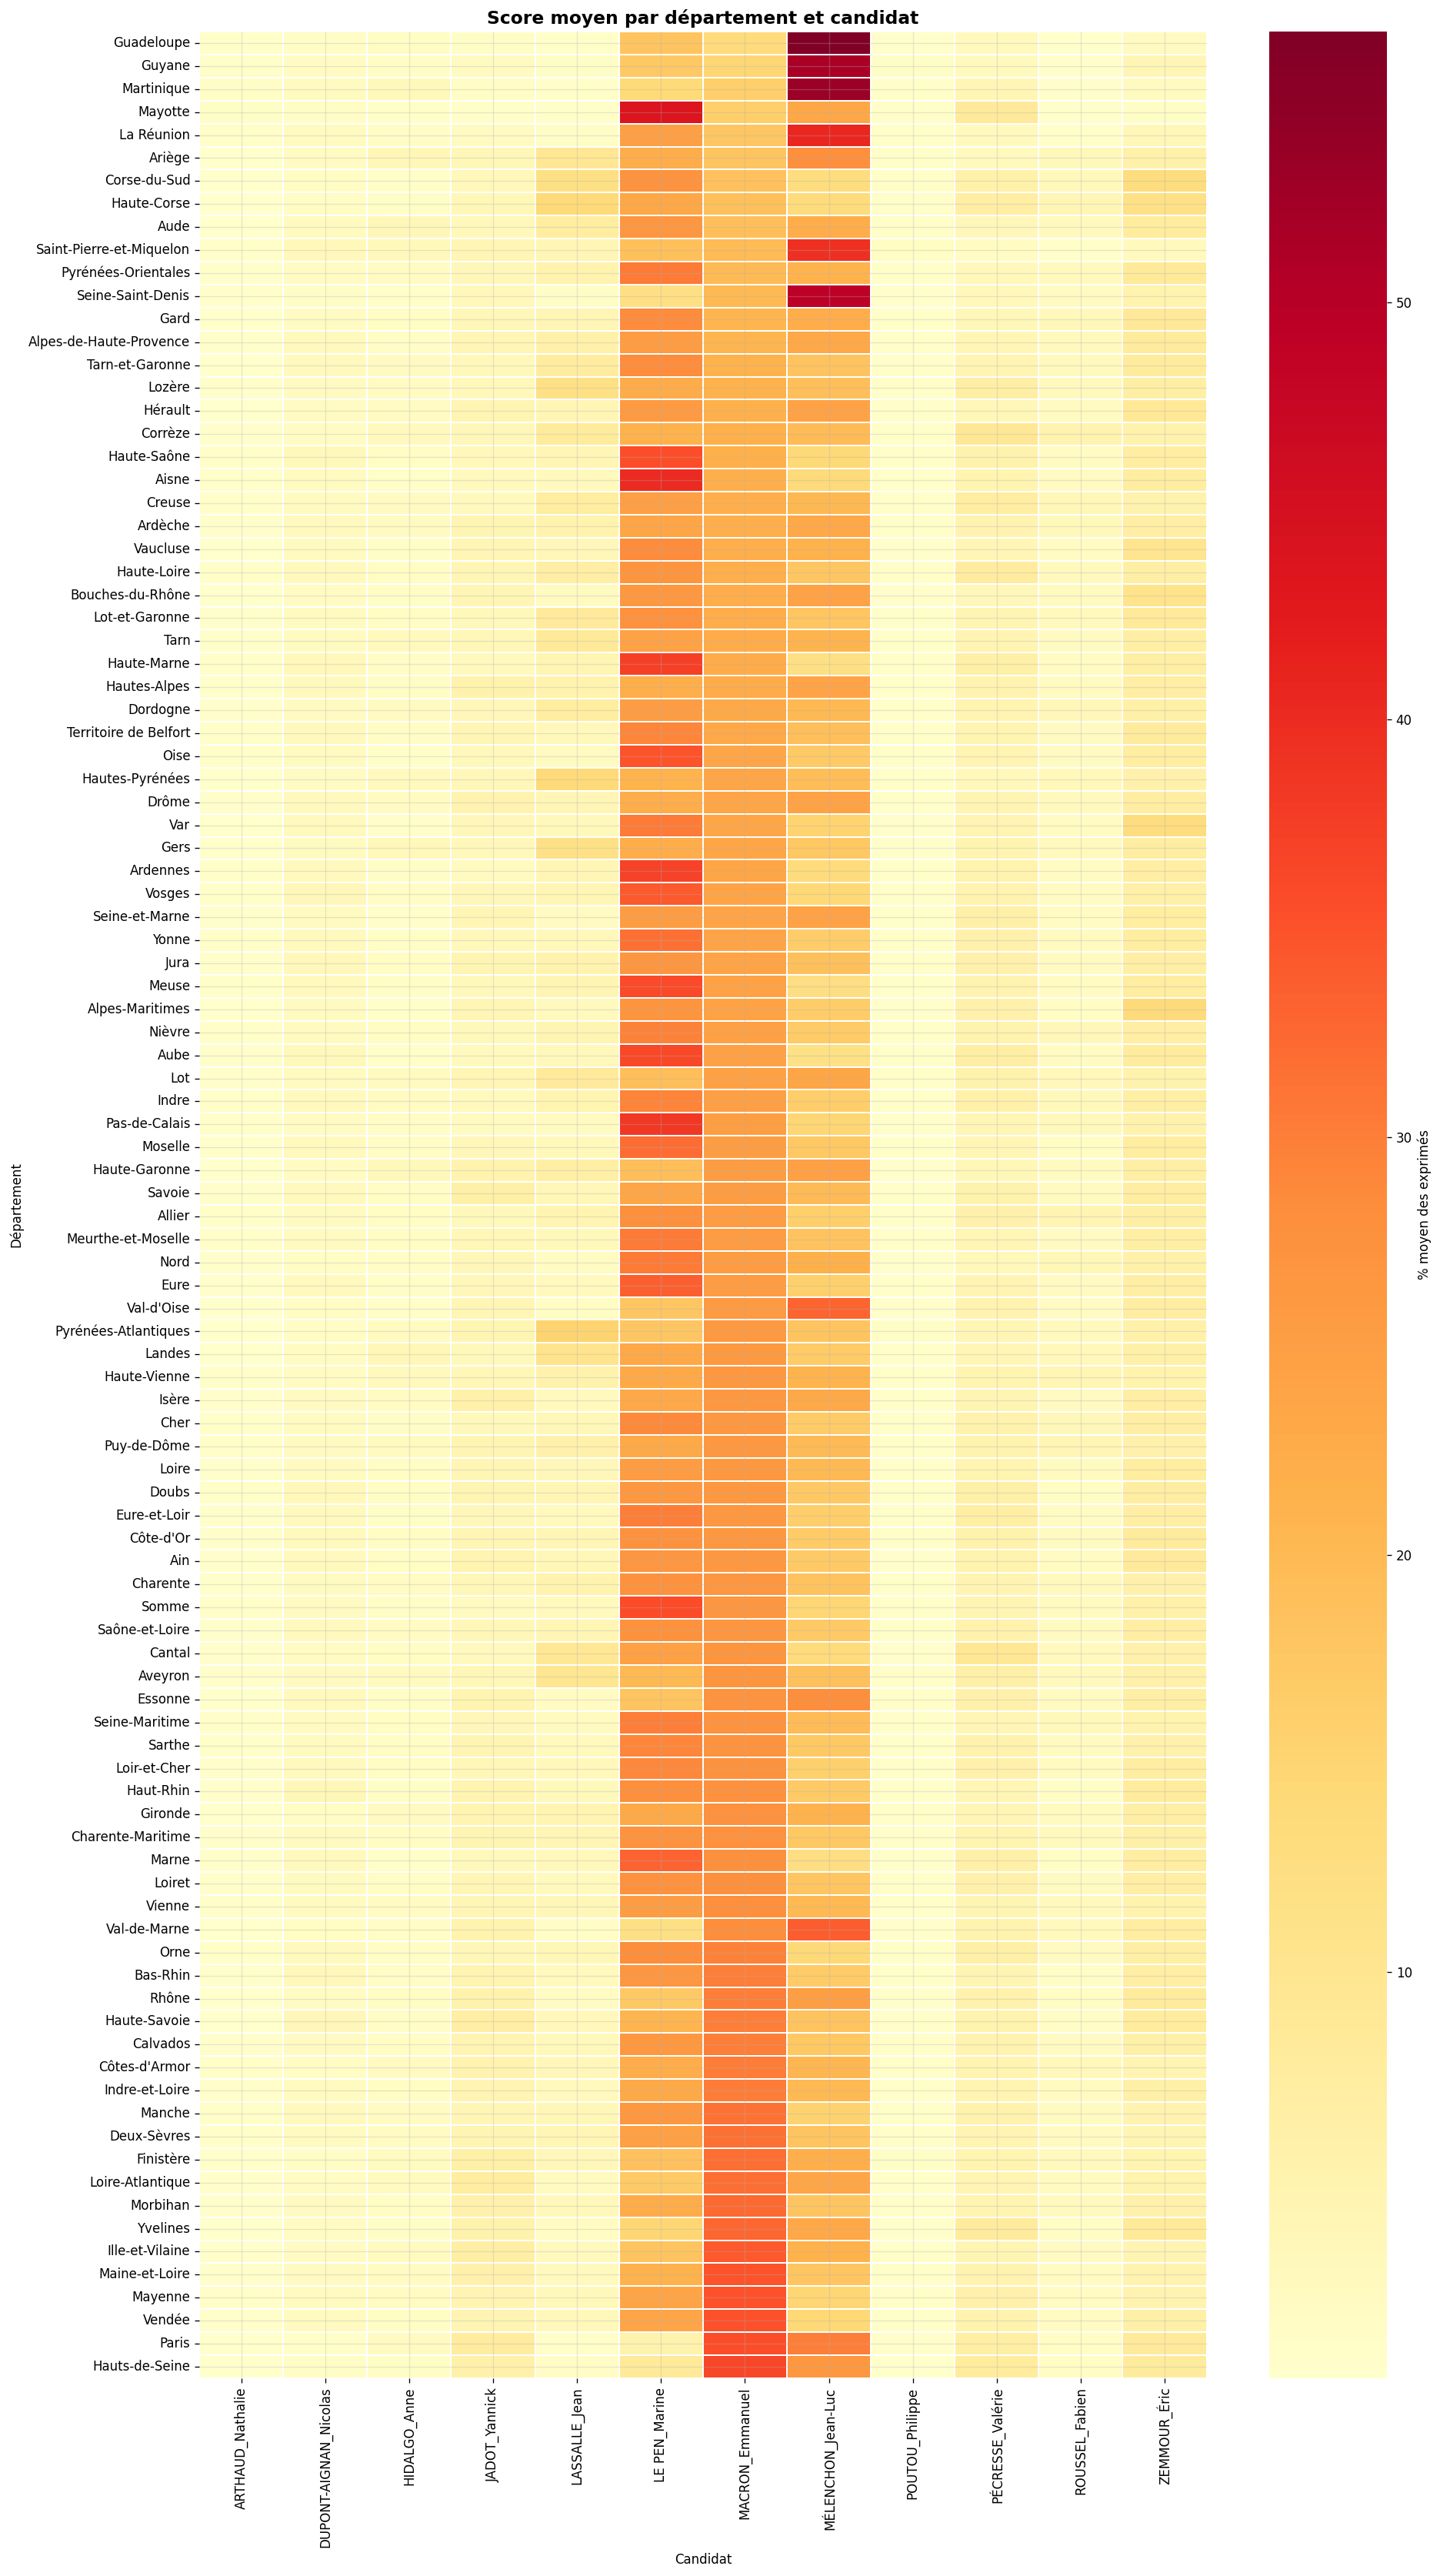

In [10]:
# Score moyen par département pour chaque candidat
dep_cand = final_df.groupby("Libellé du département")[CANDS].mean()

# Heatmap département × candidat
fig, ax = plt.subplots(figsize=(16, 28))
sns.heatmap(
    dep_cand.sort_values("MACRON_Emmanuel"),
    annot=False, cmap="YlOrRd", linewidths=0.1,
    ax=ax, cbar_kws={'label': '% moyen des exprimés'}
)
ax.set_title("Score moyen par département et candidat", fontsize=14, fontweight='bold')
ax.set_xlabel("Candidat")
ax.set_ylabel("Département")
plt.tight_layout()
plt.show()

In [11]:
# Département champion par candidat (où chaque candidat est le plus fort)
print("── Département où chaque candidat est le plus fort ──\n")
for c in sorted(CANDS, key=lambda x: dep_cand[x].max(), reverse=True):
    dep_max = dep_cand[c].idxmax()
    val_max = dep_cand[c].max()
    dep_min = dep_cand[c].idxmin()
    val_min = dep_cand[c].min()
    nom = c.split('_')[0]
    print(f"{nom:<20} → max : {dep_max:<30} ({val_max:.1f}%)  |  min : {dep_min:<30} ({val_min:.1f}%)")

── Département où chaque candidat est le plus fort ──

MÉLENCHON            → max : Guadeloupe                     (56.5%)  |  min : Aube                           (11.7%)
LE PEN               → max : Mayotte                        (43.8%)  |  min : Paris                          (5.5%)
MACRON               → max : Hauts-de-Seine                 (36.4%)  |  min : Guadeloupe                     (13.3%)
LASSALLE             → max : Pyrénées-Atlantiques           (15.2%)  |  min : Guadeloupe                     (0.7%)
ZEMMOUR              → max : Alpes-Maritimes                (13.8%)  |  min : Mayotte                        (1.2%)
PÉCRESSE             → max : Cantal                         (9.5%)  |  min : Saint-Pierre-et-Miquelon       (1.9%)
JADOT                → max : Paris                          (7.5%)  |  min : Mayotte                        (0.8%)
ROUSSEL              → max : Corrèze                        (4.9%)  |  min : Guadeloupe                     (0.5%)
HIDALGO           

## Analyse par commune

In [12]:
# Agrégation à la commune
commune_cols = ["Code du département","Libellé du département",
                "Code de la commune","Libellé de la commune"]
df_commune = final_df.groupby(commune_cols).agg(
    nb_bureaux=('id_bv','count'),
    total_inscrits=('Inscrits','sum'),
    participation_moy=('% Vot/Ins','mean'),
    **{c: (c, 'mean') for c in CANDS}
).reset_index()

print(f"Nombre de communes : {len(df_commune):,}")
print(f"\nTop 10 communes par taille (inscrits) :")
print(df_commune.nlargest(10, 'total_inscrits')[
    ['Libellé de la commune','Libellé du département','total_inscrits','nb_bureaux']
].to_string(index=False))

Nombre de communes : 34,923

Top 10 communes par taille (inscrits) :
Libellé de la commune Libellé du département  total_inscrits  nb_bureaux
                Paris                  Paris         1366407         899
            Marseille       Bouches-du-Rhône          520379         481
                 Lyon                  Rhône          292614         304
             Toulouse          Haute-Garonne          256828         263
                 Nice        Alpes-Maritimes          219968         251
               Nantes       Loire-Atlantique          196840         206
          Montpellier                Hérault          162644         138
             Bordeaux                Gironde          161634         147
           Strasbourg               Bas-Rhin          140550         144
                Lille                   Nord          127228         127


In [13]:
# Communes où chaque candidat principal domine
print("── Communes (>5000 inscrits) où chaque candidat dépasse 40% ──\n")
grandes = df_commune[df_commune['total_inscrits'] >= 5000]
for c in ['MACRON_Emmanuel','LE PEN_Marine','MÉLENCHON_Jean-Luc','ZEMMOUR_Éric']:
    top = grandes[grandes[c] >= 40][['Libellé de la commune','Libellé du département', c]]
    top = top.sort_values(c, ascending=False).head(5)
    print(f"\n{c.split('_')[0]} ≥ 40% dans {len(grandes[grandes[c]>=40])} communes :")
    print(top.to_string(index=False))

── Communes (>5000 inscrits) où chaque candidat dépasse 40% ──


MACRON ≥ 40% dans 53 communes :
 Libellé de la commune Libellé du département  MACRON_Emmanuel
Le Touquet-Paris-Plage          Pas-de-Calais        55.593333
               Bondues                   Nord        50.531250
     Neuilly-sur-Seine         Hauts-de-Seine        48.881750
            Vaucresson         Hauts-de-Seine        47.765000
               Garches         Hauts-de-Seine        45.825714

LE PEN ≥ 40% dans 62 communes :
Libellé de la commune Libellé du département  LE PEN_Marine
           Mazingarbe          Pas-de-Calais      55.584286
           Bandraboua                Mayotte      54.355000
   Bruay-la-Buissière          Pas-de-Calais      52.449444
               Auchel          Pas-de-Calais      52.415000
              Rouvroy          Pas-de-Calais      52.312000

MÉLENCHON ≥ 40% dans 149 communes :
  Libellé de la commune Libellé du département  MÉLENCHON_Jean-Luc
         Rivière-Pilote     

## Corrélations entre candidats

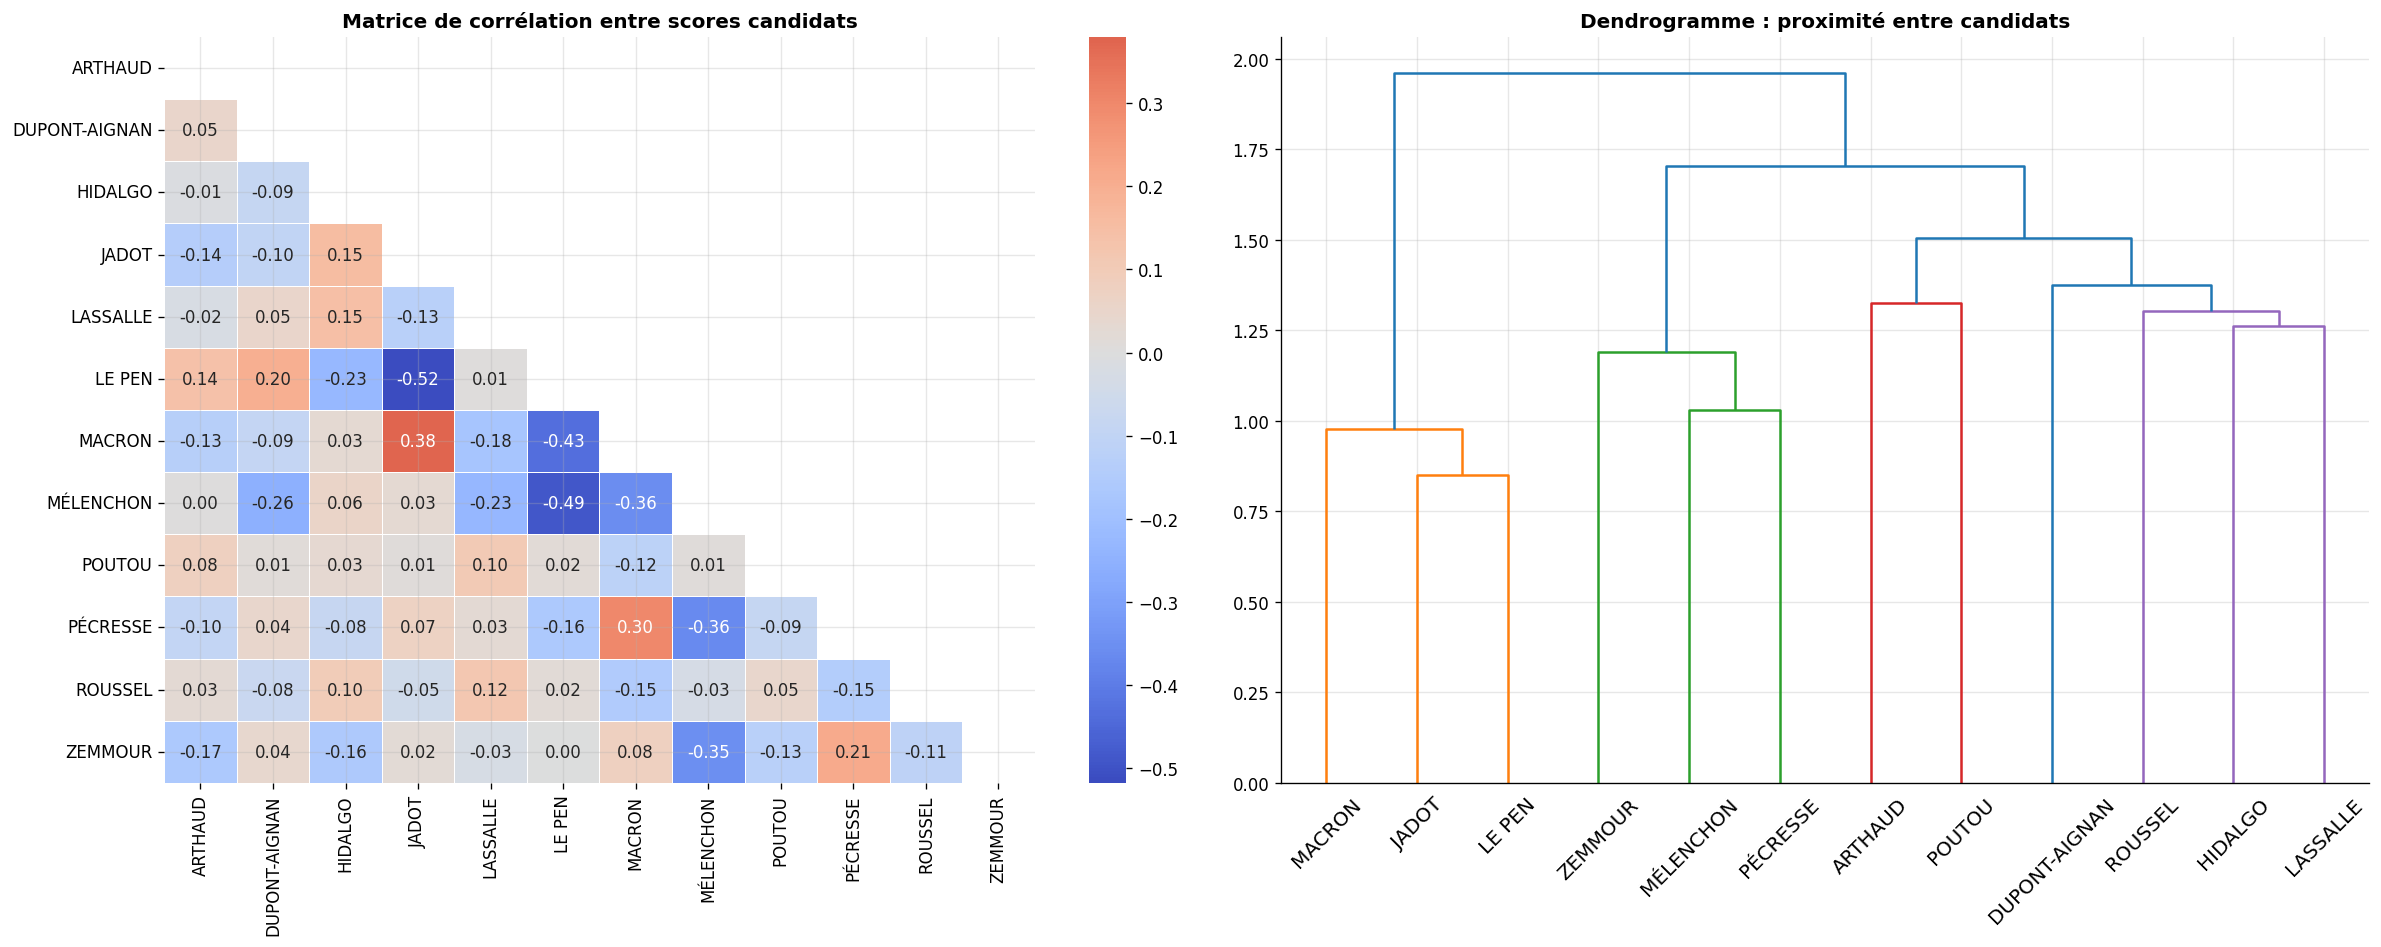


── Paires les plus corrélées (positivement) ──
  JADOT                ↔ MACRON               : r = 0.379
  MACRON               ↔ PÉCRESSE             : r = 0.300
  PÉCRESSE             ↔ ZEMMOUR              : r = 0.212
  DUPONT-AIGNAN        ↔ LE PEN               : r = 0.200
  HIDALGO              ↔ JADOT                : r = 0.153

── Paires les plus anti-corrélées ──
  MACRON               ↔ MÉLENCHON            : r = -0.357
  MÉLENCHON            ↔ PÉCRESSE             : r = -0.364
  LE PEN               ↔ MACRON               : r = -0.433
  LE PEN               ↔ MÉLENCHON            : r = -0.492
  JADOT                ↔ LE PEN               : r = -0.517


In [14]:
# Matrice de corrélation entre candidats
corr = final_df[CANDS].corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Heatmap corrélation
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=axes[0], linewidths=0.5,
            xticklabels=[c.split('_')[0] for c in CANDS],
            yticklabels=[c.split('_')[0] for c in CANDS])
axes[0].set_title("Matrice de corrélation entre scores candidats", fontweight='bold')

# Clustermap
corr_abs = corr.abs()
linkage_data = corr_abs.values
from scipy.cluster.hierarchy import linkage, dendrogram
Z = linkage(corr_abs, method='ward')
dendrogram(Z, labels=[c.split('_')[0] for c in CANDS],
           ax=axes[1], leaf_rotation=45)
axes[1].set_title("Dendrogramme : proximité entre candidats", fontweight='bold')

plt.tight_layout()
plt.show()

print("\n── Paires les plus corrélées (positivement) ──")
corr_pairs = corr.unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 0.999]
for (c1,c2), val in corr_pairs.head(10).items():
    if c1 < c2:
        print(f"  {c1.split('_')[0]:<20} ↔ {c2.split('_')[0]:<20} : r = {val:.3f}")

print("\n── Paires les plus anti-corrélées ──")
for (c1,c2), val in corr_pairs.tail(10).items():
    if c1 < c2:
        print(f"  {c1.split('_')[0]:<20} ↔ {c2.split('_')[0]:<20} : r = {val:.3f}")

##  Bureaux de vote atypiques

In [15]:
# Bureaux extrêmes pour chaque candidat
print("── Bureaux records par candidat ──\n")
for c in ['MACRON_Emmanuel','LE PEN_Marine','MÉLENCHON_Jean-Luc','ZEMMOUR_Éric']:
    idx_max = final_df[c].idxmax()
    row = final_df.loc[idx_max]
    print(f"{c.split('_')[0]:<12} → record : {row[c]:.1f}% | "
          f"{row['Libellé de la commune']} ({row['Libellé du département']}) "
          f"| id_bv : {row['id_bv']}")

# Bureaux avec participation extrême
print("\n── Bureaux avec participation < 40% ──")
bv_low = final_df[final_df["% Vot/Ins"] < 40].sort_values("% Vot/Ins")
print(f"  Nombre : {len(bv_low)}")
print(bv_low[["id_bv","Libellé de la commune","Libellé du département",
               "% Vot/Ins","Inscrits"]].head(5).to_string(index=False))

print("\n── Bureaux avec participation > 95% ──")
bv_high = final_df[final_df["% Vot/Ins"] > 95]
print(f"  Nombre : {len(bv_high)}")
print(bv_high[["id_bv","Libellé de la commune","Libellé du département",
                "% Vot/Ins","Inscrits"]].head(5).to_string(index=False))

── Bureaux records par candidat ──

MACRON       → record : 77.5% | Bigorno (Haute-Corse) | id_bv : 2B_036_0001
LE PEN       → record : 78.0% | Hardecourt-aux-Bois (Somme) | id_bv : 80_418_0001
MÉLENCHON    → record : 91.0% | Eourres (Hautes-Alpes) | id_bv : 05_047_0001
ZEMMOUR      → record : 47.8% | Cuiry-lès-Iviers (Aisne) | id_bv : 02_251_0001

── Bureaux avec participation < 40% ──
  Nombre : 448
       id_bv   Libellé de la commune Libellé du département  % Vot/Ins  Inscrits
 13_055_0799               Marseille       Bouches-du-Rhône       4.89       266
973_360_0003                  Apatou                 Guyane       7.07       608
 75_056_1599                   Paris                  Paris       7.33       901
973_311_0013 Saint-Laurent-du-Maroni                 Guyane      10.61       924
973_357_0001             Grand-Santi                 Guyane      10.96       675

── Bureaux avec participation > 95% ──
  Nombre : 60
      id_bv Libellé de la commune Libellé du départemen

In [16]:
# Vérifier le bureau suspect de Marseille
print("Bureau suspect Marseille :")
print(final_df[final_df["id_bv"] == "13_055_0799"][
    ["id_bv", "Inscrits", "Votants", "Exprimés",
     "% Vot/Ins", "MACRON_Emmanuel", "LE PEN_Marine"]
].to_string(index=False))

# Vérifier Cuiry-lès-Iviers — Zemmour 47.8%
print("\nBureau Zemmour record :")
print(final_df[final_df["id_bv"] == "02_251_0001"][
    ["id_bv", "Inscrits", "Exprimés", "ZEMMOUR_Éric",
     "MACRON_Emmanuel", "LE PEN_Marine"]
].to_string(index=False))

Bureau suspect Marseille :
      id_bv  Inscrits  Votants  Exprimés  % Vot/Ins  MACRON_Emmanuel  LE PEN_Marine
13_055_0799       266       13        13       4.89            38.46           7.69

Bureau Zemmour record :
      id_bv  Inscrits  Exprimés  ZEMMOUR_Éric  MACRON_Emmanuel  LE PEN_Marine
02_251_0001        34        23         47.83            13.04          21.74


## Clustering des bureaux de vote

In [17]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import silhouette_score, pairwise_distances
import numpy as np

# Normalisation MinMax — utilisée partout
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(final_df[CANDS].values)
print(f"X_scaled : {X_scaled.shape} — MinMaxScaler")

X_scaled : (68770, 12) — MinMaxScaler


# KMeans coude + silhouette

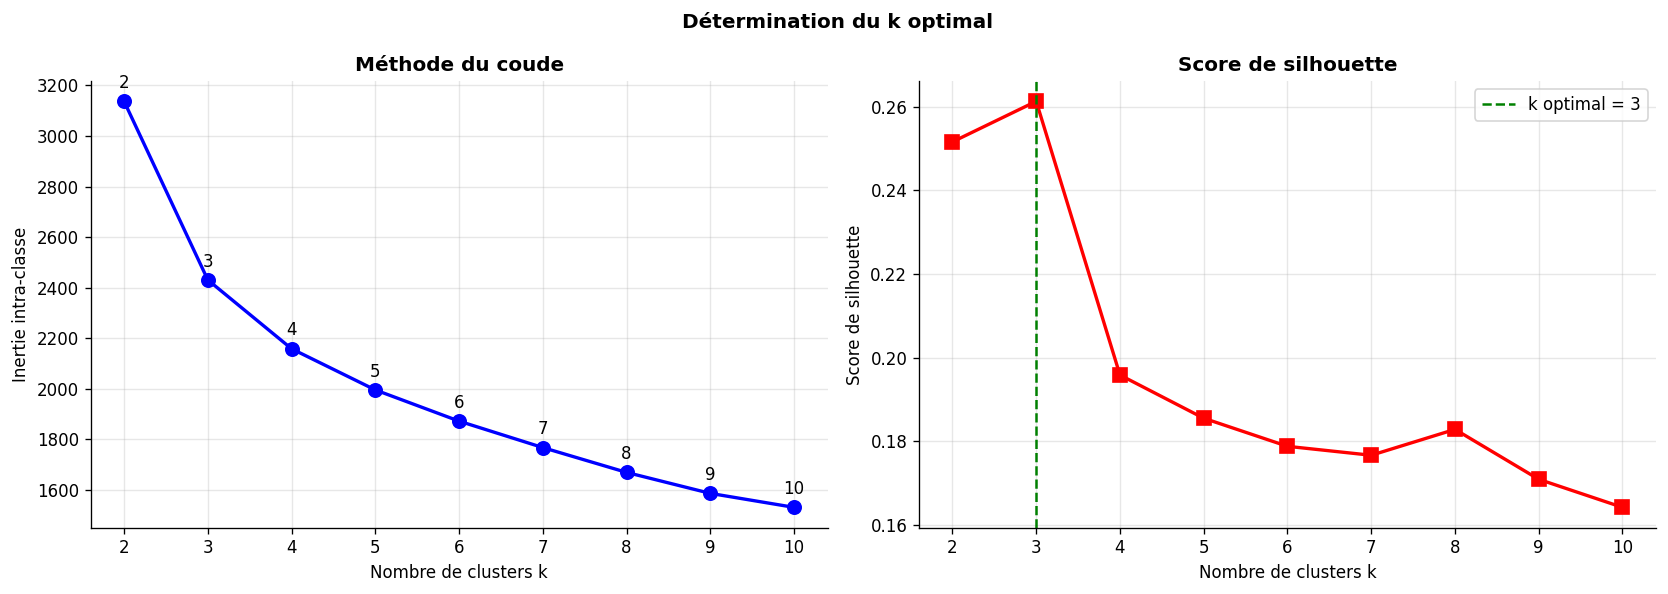

k optimal par silhouette : 3


In [18]:
inertias, silhouettes = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels, sample_size=5000))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel("Nombre de clusters k")
axes[0].set_ylabel("Inertie intra-classe")
axes[0].set_title("Méthode du coude", fontweight='bold')
for k, iner in zip(K_range, inertias):
    axes[0].annotate(str(k), (k, iner), textcoords="offset points", xytext=(0,8), ha='center')

axes[1].plot(K_range, silhouettes, 'rs-', linewidth=2, markersize=8)
axes[1].set_xlabel("Nombre de clusters k")
axes[1].set_ylabel("Score de silhouette")
axes[1].set_title("Score de silhouette", fontweight='bold')
best_k = list(K_range)[silhouettes.index(max(silhouettes))]
axes[1].axvline(best_k, color='green', linestyle='--', label=f'k optimal = {best_k}')
axes[1].legend()

plt.suptitle(" Détermination du k optimal", fontweight='bold')
plt.tight_layout()
plt.show()
print(f"k optimal par silhouette : {best_k}")

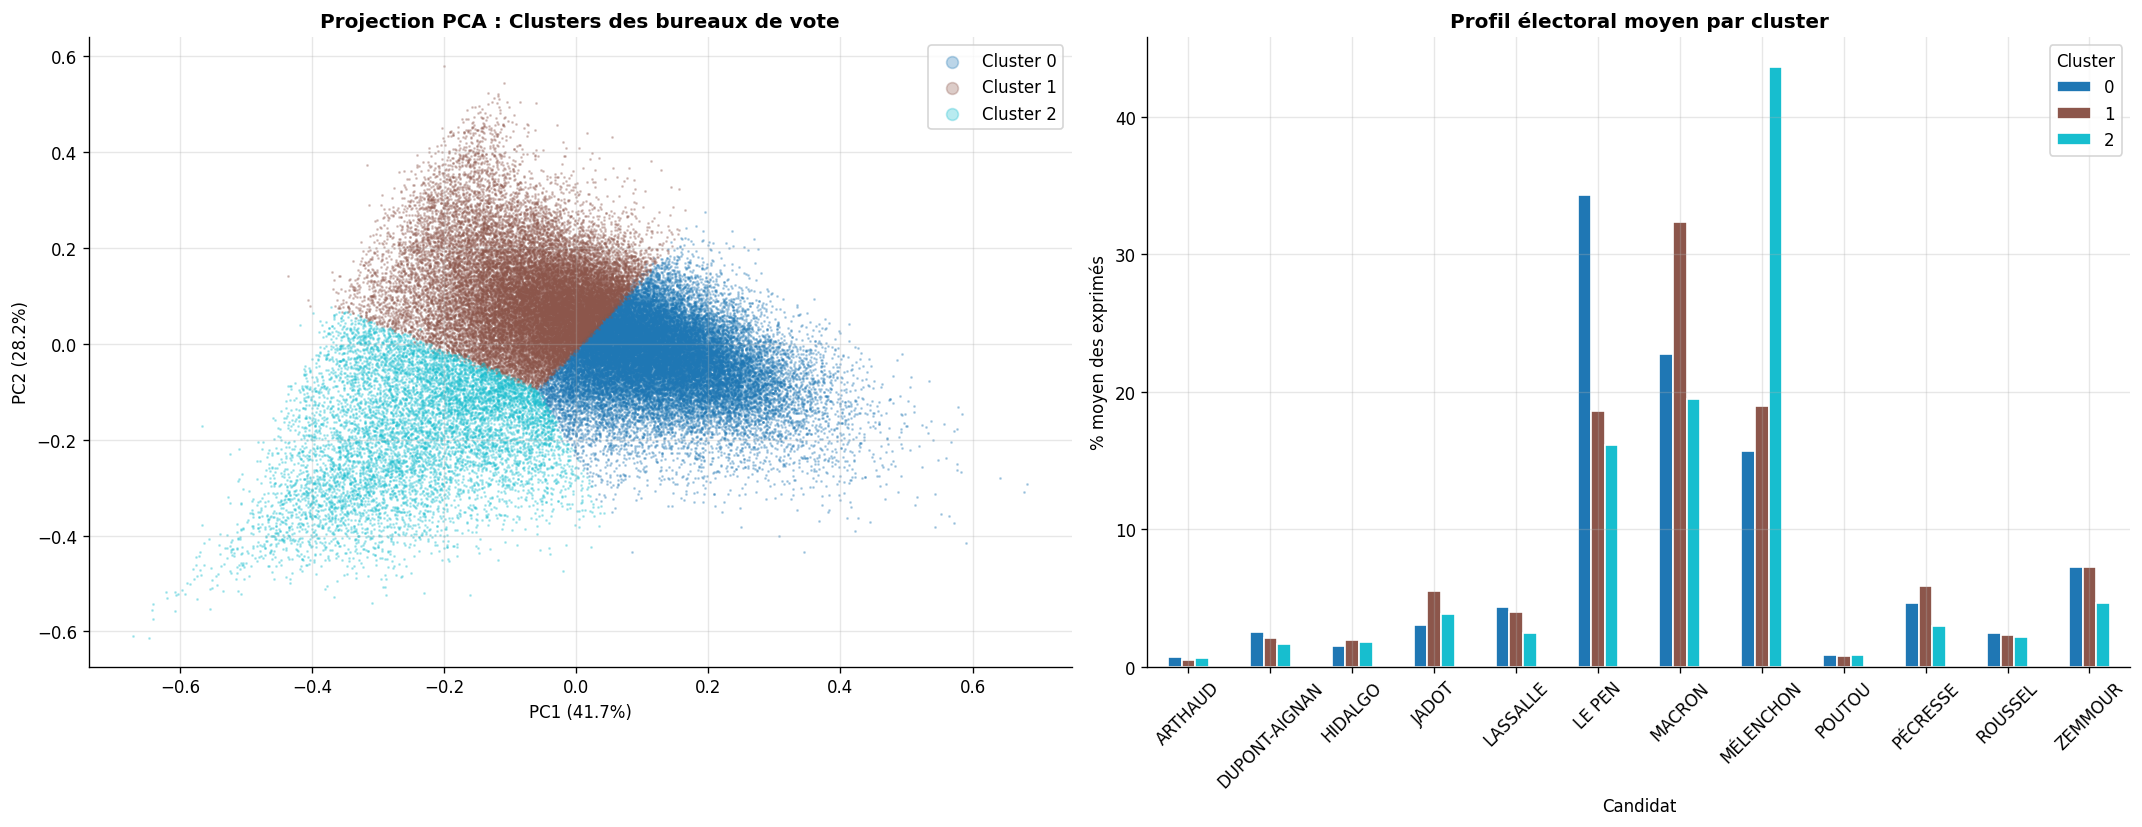


── Taille de chaque cluster ──
cluster
0    32020
1    27513
2     9237
Name: count, dtype: int64


In [19]:
# Clustering final avec k optimal
K_FINAL = best_k

km_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
final_df["cluster"] = km_final.fit_predict(X_scaled)

# PCA 2D
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
final_df["pca1"] = coords[:,0]
final_df["pca2"] = coords[:,1]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Scatter PCA coloré par cluster
palette = plt.cm.tab10(np.linspace(0, 1, K_FINAL))
for cl in range(K_FINAL):
    mask = final_df["cluster"] == cl
    axes[0].scatter(final_df.loc[mask,"pca1"], final_df.loc[mask,"pca2"],
                    c=[palette[cl]], s=0.5, alpha=0.3, label=f"Cluster {cl}")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title("Projection PCA : Clusters des bureaux de vote", fontweight='bold')
axes[0].legend(markerscale=10, framealpha=0.8)

# Profil moyen de chaque cluster
cluster_profiles = final_df.groupby("cluster")[CANDS].mean()
cluster_profiles.columns = [c.split('_')[0] for c in CANDS]
cluster_profiles.T.plot(kind='bar', ax=axes[1], colormap='tab10', edgecolor='white')
axes[1].set_xlabel("Candidat")
axes[1].set_ylabel("% moyen des exprimés")
axes[1].set_title("Profil électoral moyen par cluster", fontweight='bold')
axes[1].legend(title="Cluster", bbox_to_anchor=(1,1))
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n── Taille de chaque cluster ──")
print(final_df["cluster"].value_counts().sort_index())

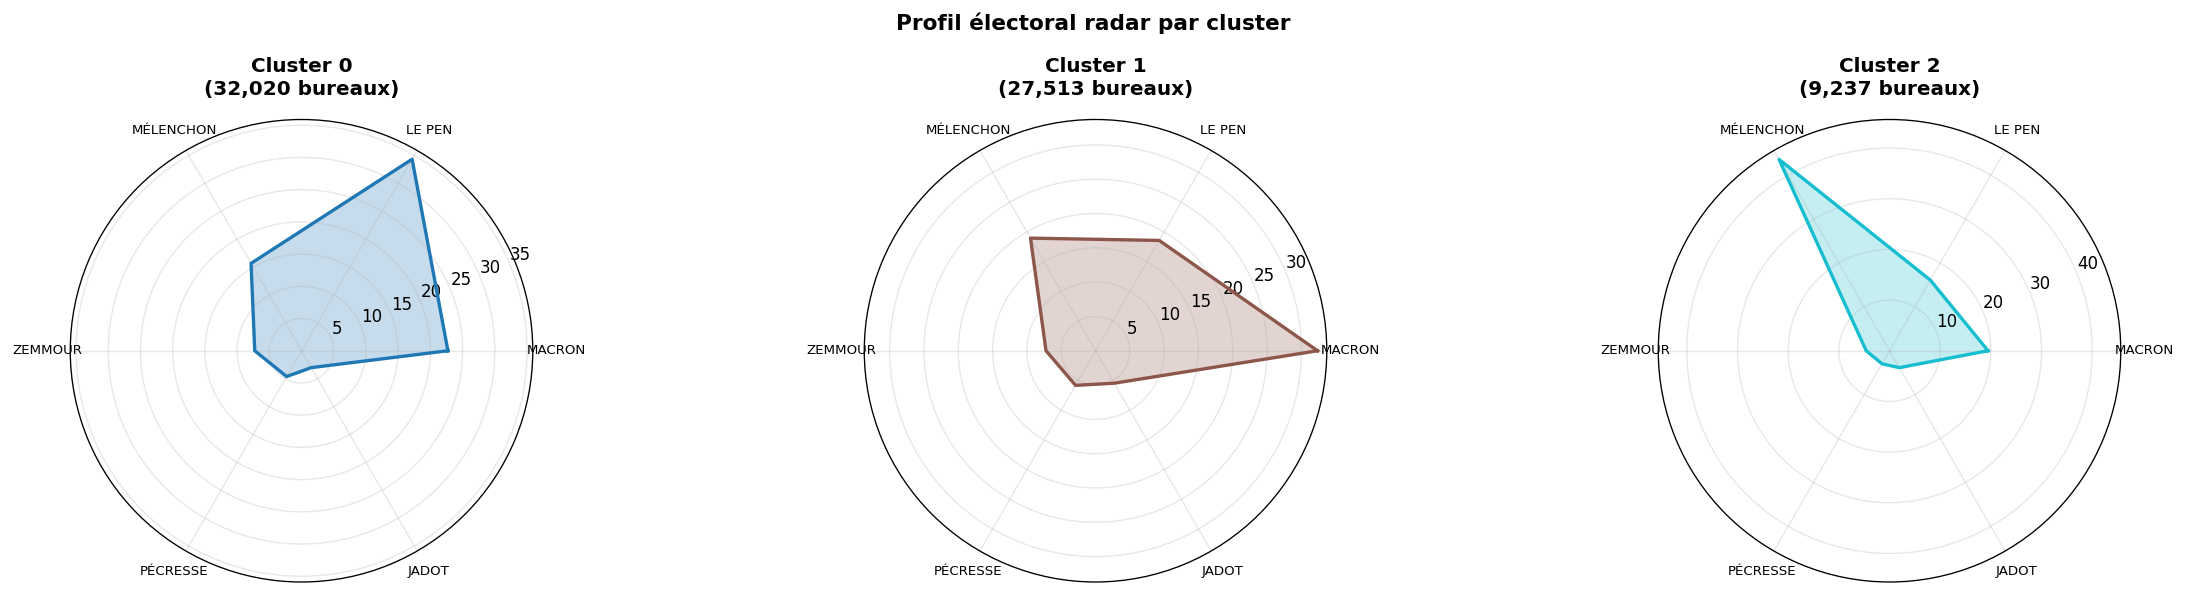

In [20]:
# Radar chart par cluster
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

# Top 6 candidats pour le radar
top6 = [c for c in sorted(CANDS, key=lambda x: final_df[x].mean(), reverse=True)][:6]
labels = [c.split('_')[0] for c in top6]
N = len(labels)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, K_FINAL, figsize=(20, 5), subplot_kw=dict(polar=True))
palette = plt.cm.tab10(np.linspace(0, 1, K_FINAL))

for cl in range(K_FINAL):
    ax = axes[cl]
    vals = cluster_profiles.loc[cl, labels].values.tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=palette[cl], linewidth=2)
    ax.fill(angles, vals, color=palette[cl], alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, size=8)
    n_bv = (final_df["cluster"]==cl).sum()
    ax.set_title(f"Cluster {cl}\n({n_bv:,} bureaux)", fontweight='bold', pad=15)

plt.suptitle("Profil électoral radar par cluster", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [21]:
# Description textuelle des clusters
print("=" * 65)
print("CARACTÉRISATION DES CLUSTERS")
print("=" * 65)

for cl in range(K_FINAL):
    subset = final_df[final_df["cluster"] == cl]
    n = len(subset)
    print(f"\n── Cluster {cl} ({n:,} bureaux, {n/len(final_df)*100:.1f}%) ──")

    # Candidat dominant
    scores = cluster_profiles.loc[cl]
    top3 = scores.sort_values(ascending=False).head(3)
    print(f"  Top 3 candidats : {', '.join([f'{c} ({v:.1f}%)' for c,v in top3.items()])}")

    # Participation
    part = subset["% Vot/Ins"].mean()
    print(f"  Participation moyenne : {part:.1f}%")

    # Taille des bureaux
    ins = subset["Inscrits"].mean()
    print(f"  Taille moy. bureau : {ins:.0f} inscrits")

    # Représentation géographique
    top_deps = subset["Libellé du département"].value_counts().head(3)
    print(f"  Départements sur-représentés : {', '.join(top_deps.index.tolist())}")

CARACTÉRISATION DES CLUSTERS

── Cluster 0 (32,020 bureaux, 46.6%) ──
  Top 3 candidats : LE PEN (34.3%), MACRON (22.7%), MÉLENCHON (15.7%)
  Participation moyenne : 77.2%
  Taille moy. bureau : 555 inscrits
  Départements sur-représentés : Pas-de-Calais, Nord, Aisne

── Cluster 1 (27,513 bureaux, 40.0%) ──
  Top 3 candidats : MACRON (32.4%), MÉLENCHON (19.0%), LE PEN (18.6%)
  Participation moyenne : 78.7%
  Taille moy. bureau : 775 inscrits
  Départements sur-représentés : Loire-Atlantique, Rhône, Hauts-de-Seine

── Cluster 2 (9,237 bureaux, 13.4%) ──
  Top 3 candidats : MÉLENCHON (43.6%), MACRON (19.4%), LE PEN (16.1%)
  Participation moyenne : 67.0%
  Taille moy. bureau : 840 inscrits
  Départements sur-représentés : La Réunion, Seine-Saint-Denis, Guadeloupe


# Graph Laplacian

RAM estimée pour A : 200 MB


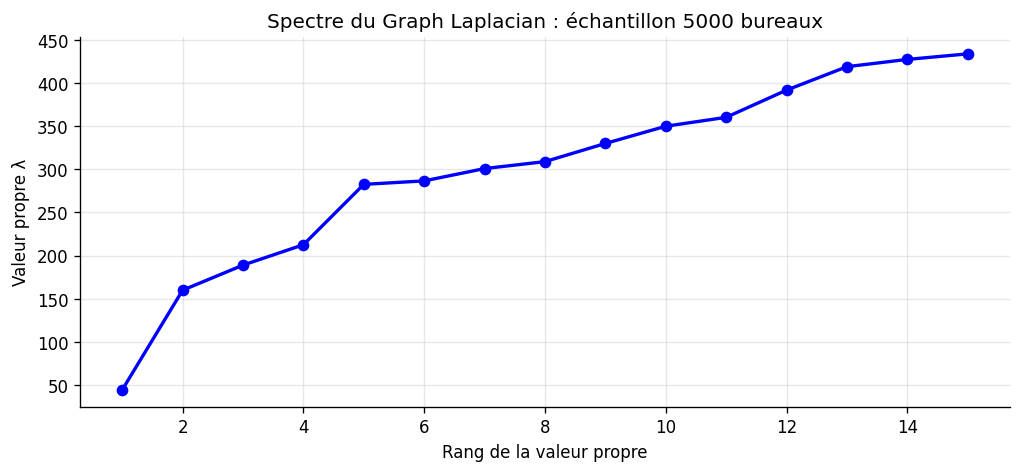

k optimal KMeans   : 3


In [22]:
# ── Échantillon pour le Graph Laplacian
SAMPLE_SIZE = 5000
np.random.seed(42)
sample_idx = np.random.choice(len(final_df), size=SAMPLE_SIZE, replace=False)
X_sample = X_scaled[sample_idx]  # ← utiliser X_scaled déjà calculé en CELLULE A

print(f"RAM estimée pour A : {SAMPLE_SIZE**2 * 8 / 1e6:.0f} MB")

D = pairwise_distances(X_sample, metric='euclidean')
sigma = np.median(D)
A = np.exp(-D**2 / (2 * sigma**2))
deg = A.sum(axis=1)
L = np.diag(deg) - A

eigenvalues, _ = np.linalg.eigh(L)
eigenvalues_sorted = np.sort(eigenvalues)

plt.figure(figsize=(10, 4))
plt.plot(range(1, 16), eigenvalues_sorted[1:16], 'bo-', linewidth=2)
plt.xlabel("Rang de la valeur propre")
plt.ylabel("Valeur propre λ")
plt.title(f"Spectre du Graph Laplacian : échantillon {SAMPLE_SIZE} bureaux")
plt.grid(True, alpha=0.3)
plt.show()

gaps = np.diff(eigenvalues_sorted[1:16])
k_optimal = gaps.argmax() + 2
print(f"k optimal KMeans   : {best_k}")



## UMAP : Réduction dimensionnelle
> UMAP construit un graphe de voisinage local équivalent au Graph Laplacian, mais avec une complexité O(n·k) au lieu de O(n²). C'est la version non-linéaire du spectral embedding.

Calcul UMAP en cours (2-5 min)...
UMAP(n_jobs=1, n_neighbors=30, random_state=42, verbose=True)
Sat Jul 18 12:15:51 2026 Construct fuzzy simplicial set
Sat Jul 18 12:15:51 2026 Finding Nearest Neighbors
Sat Jul 18 12:15:51 2026 Building RP forest with 18 trees
Sat Jul 18 12:15:56 2026 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	Stopping threshold met -- exiting after 2 iterations
Sat Jul 18 12:16:24 2026 Finished Nearest Neighbor Search
Sat Jul 18 12:16:32 2026 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Sat Jul 18 12:18:01 2026 Finished embedding

✓ UMAP terminé : (68770, 2)
  Espace original : 12 dimensions (12 candidats)
  Espace UMAP     : 2 dimensions


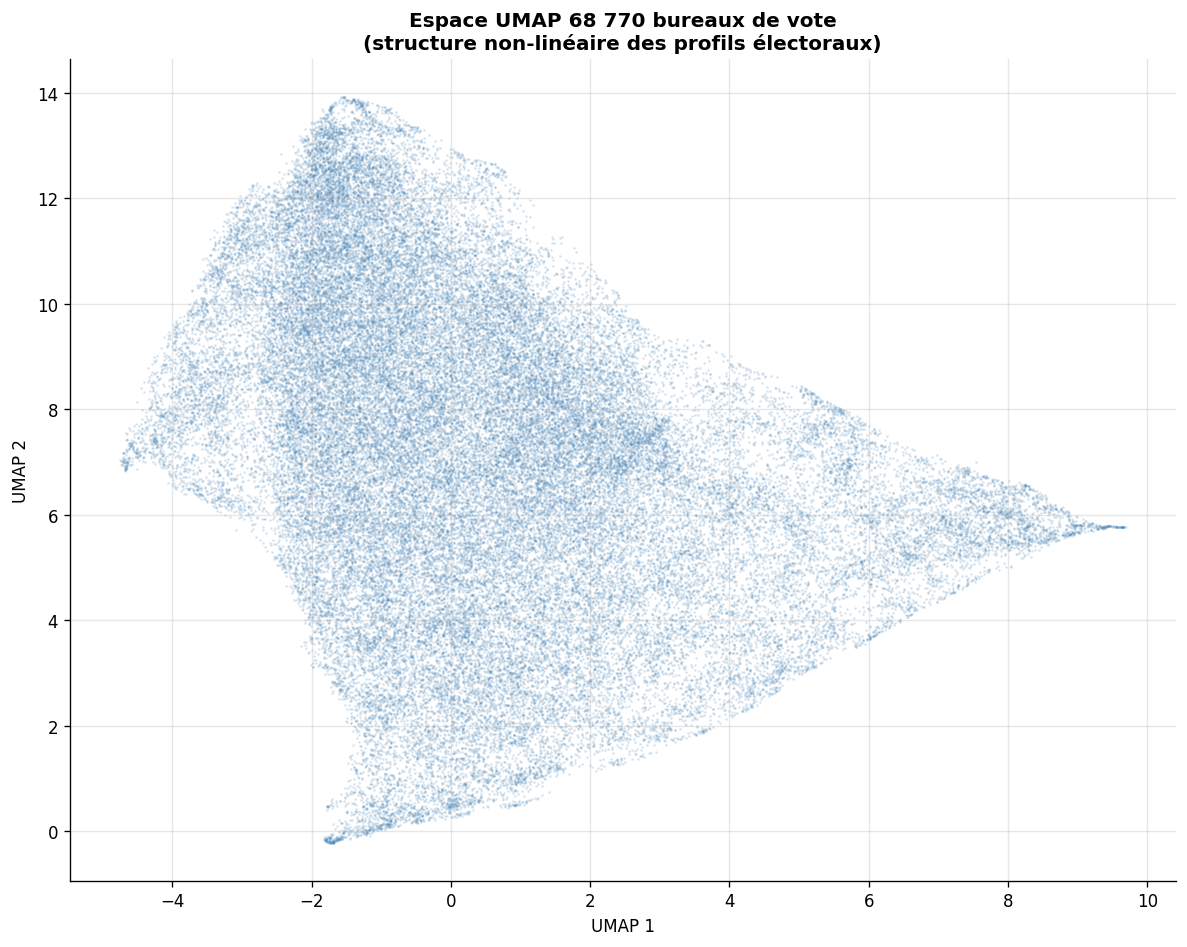

In [23]:
!pip install umap-learn -q
import umap

print("Calcul UMAP en cours (2-5 min)...")
reducer = umap.UMAP(
    n_components=2,   # réduire à 2D pour visualisation et clustering
    n_neighbors=30,   # taille du voisinage local — équivalent à la matrice d'adjacence
    min_dist=0.1,     # compacité des clusters dans l'espace projeté
    metric='euclidean',
    random_state=42,
    verbose=True
)

embedding = reducer.fit_transform(X_scaled)
final_df["umap1"] = embedding[:, 0]
final_df["umap2"] = embedding[:, 1]

print(f"\n✓ UMAP terminé : {embedding.shape}")
print(f"  Espace original : {X_scaled.shape[1]} dimensions (12 candidats)")
print(f"  Espace UMAP     : 2 dimensions")

# Visualisation de l'espace UMAP brut (sans clustering)
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(embedding[:, 0], embedding[:, 1],
           s=0.3, alpha=0.2, color='steelblue')
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("Espace UMAP 68 770 bureaux de vote\n(structure non-linéaire des profils électoraux)",
             fontweight='bold')
plt.tight_layout()
plt.show()

## KMeans sur espace UMAP — Détermination du k optimal

KMeans sur espace UMAP :
    k   silhouette  tailles
-----------------------------------------------------------------
    3        0.429  → [31903, 21253, 15614]
    4        0.384  → [23124, 19817, 14773, 11056]
    5        0.417  → [16092, 14981, 14416, 14023, 9258]
    6        0.392  → [15534, 13992, 13461, 10086, 8903, 6794]
    7        0.382  → [12979, 12735, 11403, 10091, 7784, 7431, 6347]
    8        0.378  → [10603, 10106, 9441, 9436, 9169, 7377, 6512, 6126]


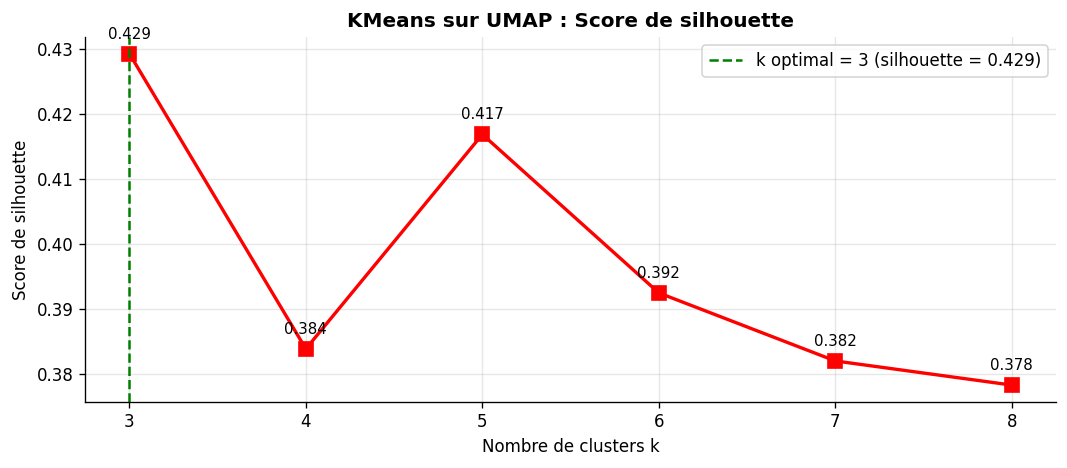


✓ k optimal sur UMAP : 3
  (rappel : k optimal KMeans brut = 3)


In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

print("KMeans sur espace UMAP :")
print(f"{'k':>5} {'silhouette':>12}  {'tailles'}")
print("-" * 65)

sil_umap   = []
K_range_umap = range(3, 9)

for k in K_range_umap:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embedding)
    sil = silhouette_score(embedding, labels, sample_size=5000)
    sil_umap.append(sil)
    sizes = sorted(pd.Series(labels).value_counts().tolist(), reverse=True)
    print(f"{k:>5} {sil:>12.3f}  → {sizes}")

# Visualisation silhouette
best_k_umap = list(K_range_umap)[sil_umap.index(max(sil_umap))]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(K_range_umap, sil_umap, 'rs-', linewidth=2, markersize=8)
ax.axvline(best_k_umap, color='green', linestyle='--',
           label=f'k optimal = {best_k_umap} (silhouette = {max(sil_umap):.3f})')
for k, s in zip(K_range_umap, sil_umap):
    ax.annotate(f"{s:.3f}", (k, s), textcoords="offset points",
                xytext=(0, 9), ha='center', fontsize=9)
ax.set_xlabel("Nombre de clusters k")
ax.set_ylabel("Score de silhouette")
ax.set_title("KMeans sur UMAP : Score de silhouette", fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print(f"\n✓ k optimal sur UMAP : {best_k_umap}")
print(f"  (rappel : k optimal KMeans brut = {best_k})")

## Clustering final — KMeans sur UMAP


── Taille des clusters ──
cluster_umap
0    31903
1    21253
2    15614
Name: count, dtype: int64


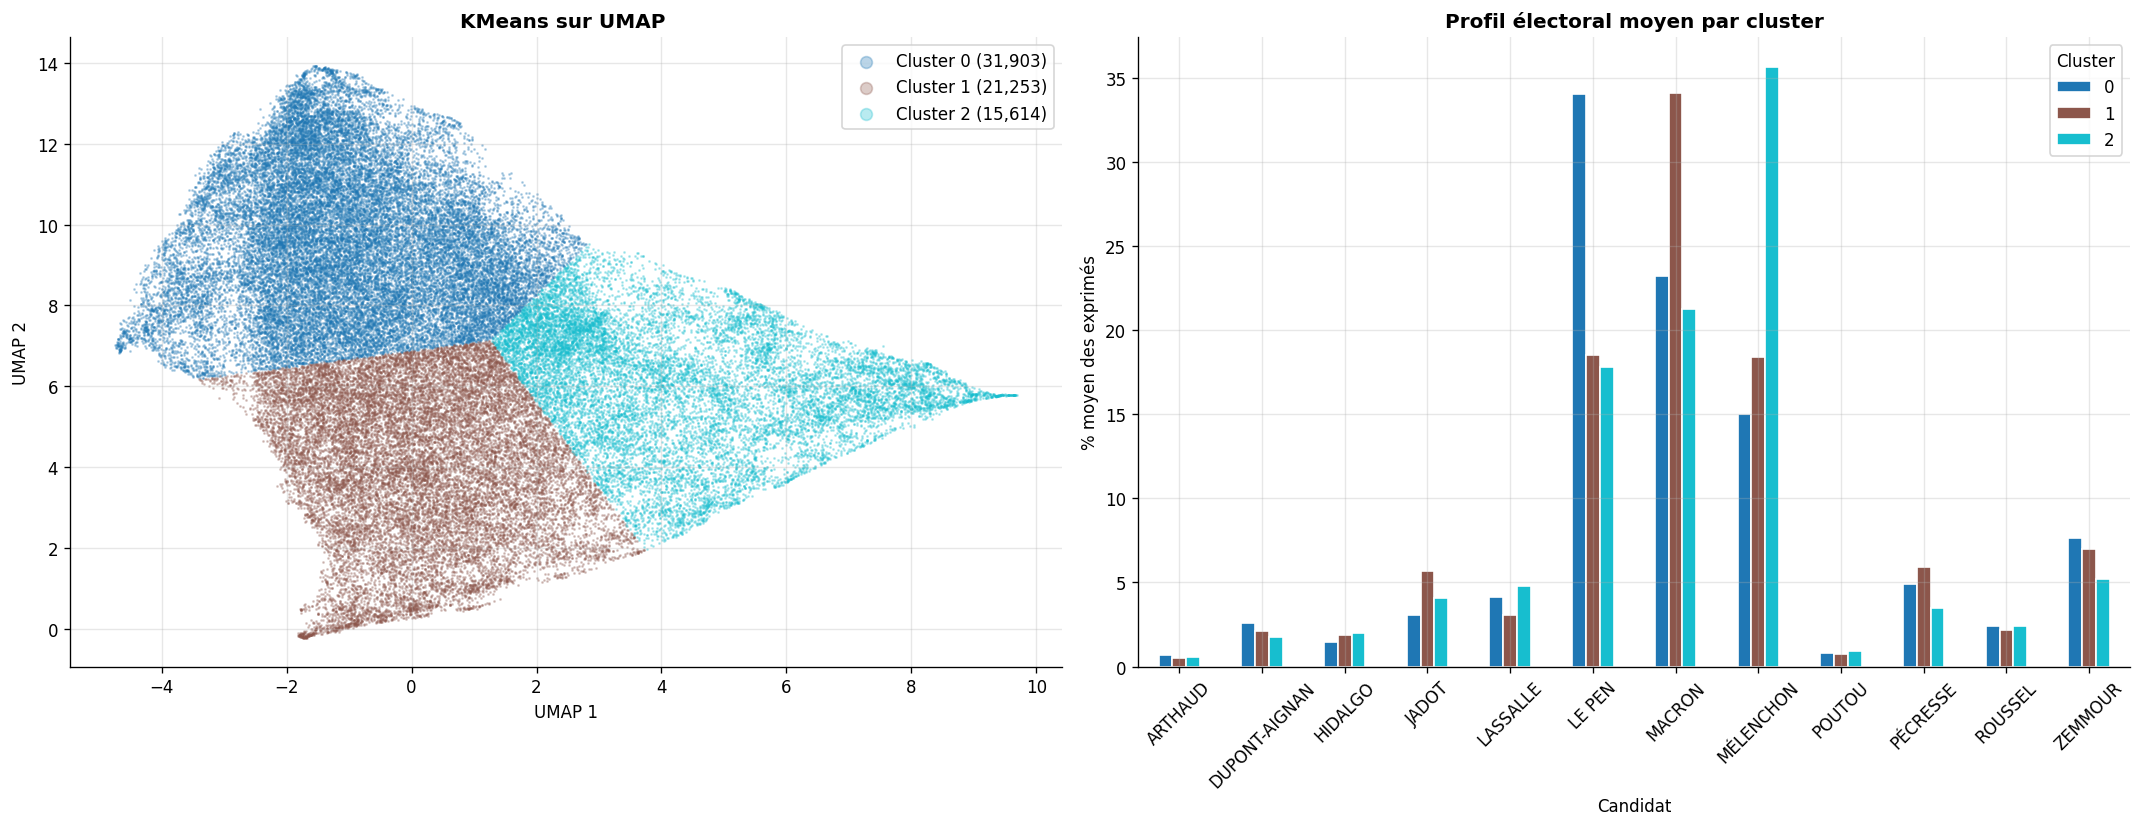

In [25]:
K_FINAL_UMAP = 3

km_umap_final = KMeans(n_clusters=K_FINAL_UMAP, random_state=42, n_init=10)
final_df["cluster_umap"] = km_umap_final.fit_predict(embedding)

print("── Taille des clusters ──")
print(final_df["cluster_umap"].value_counts().sort_index())

# ── Visualisation 1 : scatter UMAP coloré
palette = plt.cm.tab10(np.linspace(0, 1, K_FINAL_UMAP))
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for cl in range(K_FINAL_UMAP):
    mask = final_df["cluster_umap"] == cl
    axes[0].scatter(final_df.loc[mask,"umap1"], final_df.loc[mask,"umap2"],
                    c=[palette[cl]], s=0.5, alpha=0.3,
                    label=f"Cluster {cl} ({mask.sum():,})")
axes[0].set_xlabel("UMAP 1")
axes[0].set_ylabel("UMAP 2")
axes[0].set_title("KMeans sur UMAP ", fontweight='bold')
axes[0].legend(markerscale=10, framealpha=0.8)

# ── Visualisation 2 : profil électoral moyen
umap_profiles = final_df.groupby("cluster_umap")[CANDS].mean()
umap_profiles.columns = [c.split('_')[0] for c in CANDS]
umap_profiles.T.plot(kind='bar', ax=axes[1], colormap='tab10', edgecolor='white')
axes[1].set_xlabel("Candidat")
axes[1].set_ylabel("% moyen des exprimés")
axes[1].set_title("Profil électoral moyen par cluster", fontweight='bold')
axes[1].legend(title="Cluster", bbox_to_anchor=(1,1))
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

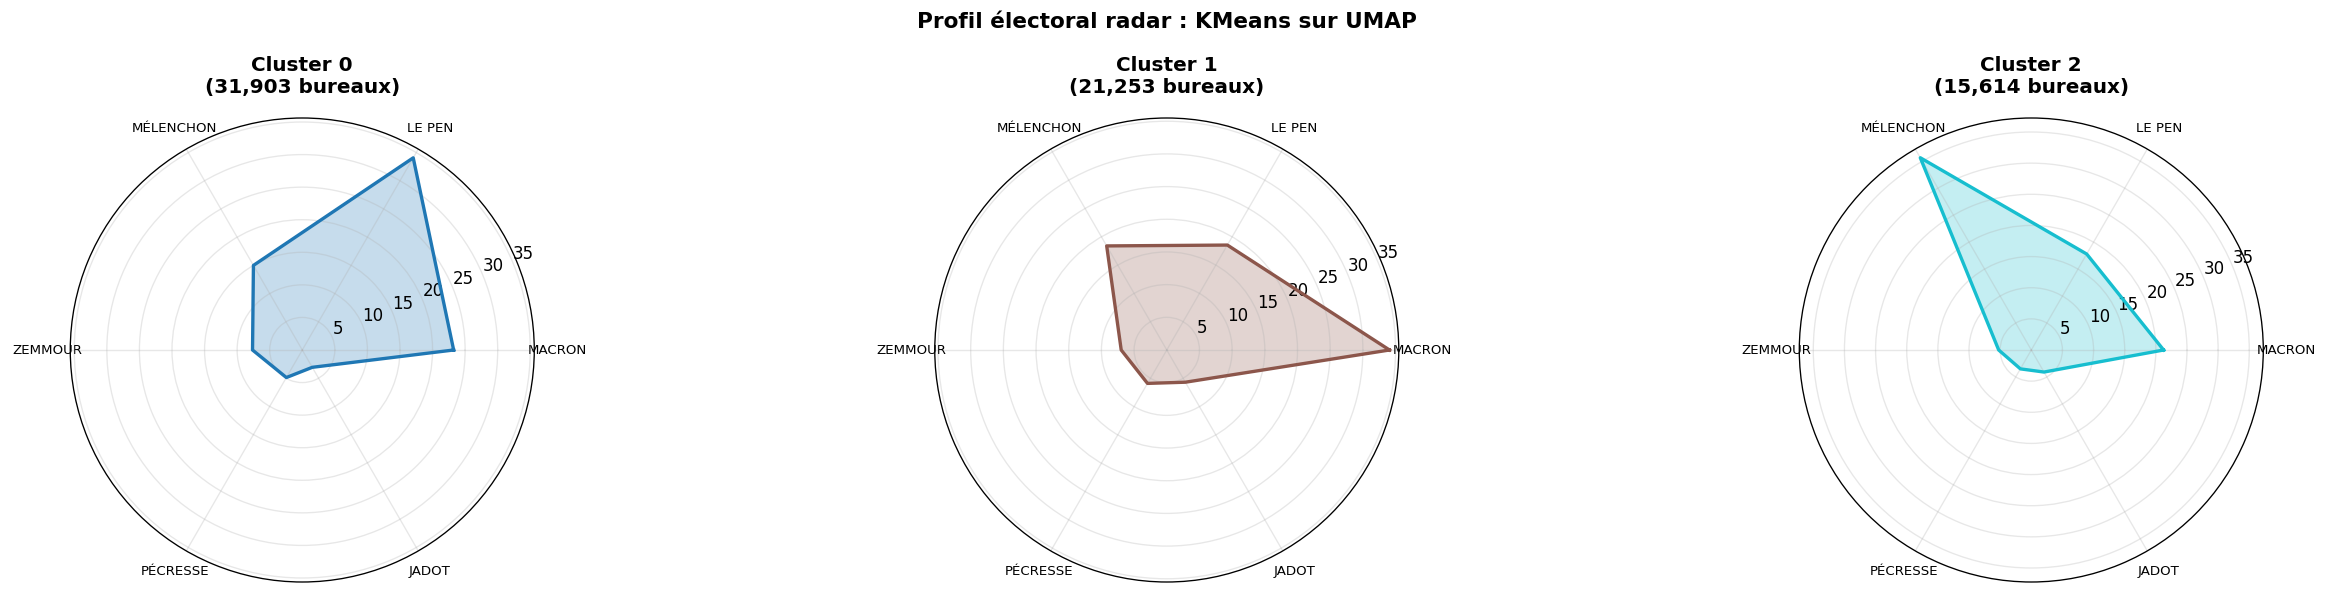

In [26]:
# ── Radar chart
top6 = sorted(CANDS, key=lambda x: final_df[x].mean(), reverse=True)[:6]
labels_radar = [c.split('_')[0] for c in top6]
N = len(labels_radar)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist() +          np.linspace(0, 2*np.pi, N, endpoint=False).tolist()[:1]

fig, axes = plt.subplots(1, K_FINAL_UMAP, figsize=(22, 5), subplot_kw=dict(polar=True))
palette = plt.cm.tab10(np.linspace(0, 1, K_FINAL_UMAP))

for cl in range(K_FINAL_UMAP):
    ax = axes[cl]
    vals = umap_profiles.loc[cl, labels_radar].values.tolist() +            umap_profiles.loc[cl, labels_radar].values.tolist()[:1]
    ax.plot(angles, vals, color=palette[cl], linewidth=2)
    ax.fill(angles, vals, color=palette[cl], alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels_radar, size=8)
    n_bv = (final_df["cluster_umap"] == cl).sum()
    ax.set_title(f"Cluster {cl}\n({n_bv:,} bureaux)", fontweight='bold', pad=15)

plt.suptitle("Profil électoral radar : KMeans sur UMAP", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [27]:
# ── Caractérisation textuelle
print("=" * 65)
print("CARACTÉRISATION DES CLUSTERS — KMeans sur UMAP")
print("=" * 65)

for cl in range(K_FINAL_UMAP):
    subset = final_df[final_df["cluster_umap"] == cl]
    n = len(subset)
    print(f"\n── Cluster {cl} ({n:,} bureaux, {n/len(final_df)*100:.1f}%) ──")

    scores = umap_profiles.loc[cl].sort_values(ascending=False)
    top3   = scores.head(3)
    print(f"  Top 3 candidats : {', '.join([f'{c} ({v:.1f}%)' for c,v in top3.items()])}")
    print(f"  Participation   : {subset['% Vot/Ins'].mean():.1f}%")
    print(f"  Taille moy.     : {subset['Inscrits'].mean():.0f} inscrits/bureau")
    top_deps = subset["Libellé du département"].value_counts().head(3)
    print(f"  Départements    : {', '.join(top_deps.index.tolist())}")

# ── Comparaison KMeans brut vs KMeans UMAP
print("\n" + "=" * 65)
print("COMPARAISON KMeans brut vs KMeans UMAP")
print("=" * 65)
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
ari = adjusted_rand_score(final_df["cluster"], final_df["cluster_umap"])
nmi = normalized_mutual_info_score(final_df["cluster"], final_df["cluster_umap"])
print(f"\nAdjusted Rand Index (ARI)           : {ari:.3f}")
print(f"Normalized Mutual Information (NMI) : {nmi:.3f}")
print(f"\nARI proche de 1 → clusters cohérents entre les deux méthodes")
print(pd.crosstab(final_df["cluster"], final_df["cluster_umap"],
                  rownames=["KMeans brut"], colnames=["KMeans UMAP"]))

CARACTÉRISATION DES CLUSTERS — KMeans sur UMAP

── Cluster 0 (31,903 bureaux, 46.4%) ──
  Top 3 candidats : LE PEN (34.1%), MACRON (23.2%), MÉLENCHON (15.0%)
  Participation   : 77.5%
  Taille moy.     : 555 inscrits/bureau
  Départements    : Pas-de-Calais, Nord, Aisne

── Cluster 1 (21,253 bureaux, 30.9%) ──
  Top 3 candidats : MACRON (34.1%), LE PEN (18.5%), MÉLENCHON (18.4%)
  Participation   : 78.9%
  Taille moy.     : 827 inscrits/bureau
  Départements    : Loire-Atlantique, Hauts-de-Seine, Rhône

── Cluster 2 (15,614 bureaux, 22.7%) ──
  Top 3 candidats : MÉLENCHON (35.6%), MACRON (21.2%), LE PEN (17.8%)
  Participation   : 71.0%
  Taille moy.     : 741 inscrits/bureau
  Départements    : La Réunion, Seine-Saint-Denis, Pyrénées-Atlantiques

COMPARAISON KMeans brut vs KMeans UMAP

Adjusted Rand Index (ARI)           : 0.688
Normalized Mutual Information (NMI) : 0.631

ARI proche de 1 → clusters cohérents entre les deux méthodes
KMeans UMAP      0      1     2
KMeans brut         

In [28]:
#  la méthode retenue
final_df["cluster_final"] = final_df["cluster_umap"]

print("Méthode retenue : KMeans sur UMAP (k=3)")
print("Silhouette : 0.429")
print(final_df["cluster_final"].value_counts().sort_index())


Méthode retenue : KMeans sur UMAP (k=3)
Silhouette : 0.429
cluster_final
0    31903
1    21253
2    15614
Name: count, dtype: int64


## Export de la base finale

In [29]:
output_path = "/content/drive/MyDrive/Stage/resultats_t1_bureaux.csv"

# Colonnes à exporter pour la suite du pipeline
cols_export = (
    ["id_bv", "Code du département", "Libellé du département",
     "Code de la commune", "Libellé de la commune",
     "Inscrits", "% Vot/Ins", "Exprimés"]
  + CANDS

)

final_df[cols_export].to_csv(output_path, index=False)

print(f"✓ Base exportée : {output_path}")
print(f"  Dimensions     : {final_df.shape}")

print(f"\n── Résumé final ──")
print(f"  Bureaux analysés    : {len(final_df):,}")
print(f"  Candidats           : {len(CANDS)}")
final_df.head()

✓ Base exportée : /content/drive/MyDrive/Stage/resultats_t1_bureaux.csv
  Dimensions     : (68770, 31)

── Résumé final ──
  Bureaux analysés    : 68,770
  Candidats           : 12


,id_bv,ARTHAUD_Nathalie,DUPONT-AIGNAN_Nicolas,HIDALGO_Anne,JADOT_Yannick,LASSALLE_Jean,LE PEN_Marine,MACRON_Emmanuel,MÉLENCHON_Jean-Luc,POUTOU_Philippe,...,% Vot/Ins,Exprimés,% Exp/Vot,cluster,pca1,pca2,umap1,umap2,cluster_umap,cluster_final
0,01_001_0001,0.58,4.04,0.96,5.77,3.46,28.65,28.85,12.69,0.58,...,83.26,520,96.83,0,0.076329,0.075801,-1.830647,7.189190,0,0
1,01_002_0001,1.17,0.00,1.75,5.85,5.85,13.45,29.24,23.98,1.75,...,82.16,171,97.71,1,-0.148812,0.061668,2.000669,4.384154,1,1
2,01_004_0001,0.48,1.55,1.79,2.98,2.86,28.21,18.93,25.71,0.95,...,76.44,840,97.33,0,0.011040,-0.105207,2.370054,8.996140,0,0
3,01_004_0002,0.71,2.38,2.26,5.46,2.26,24.94,23.87,23.04,0.48,...,76.51,842,97.57,1,-0.020429,-0.022257,1.063052,6.605560,1,1
4,01_004_0003,0.84,2.00,1.69,6.85,2.95,23.92,24.13,23.92,0.32,...,79.72,949,98.14,1,-0.040799,-0.022028,1.277620,6.006215,1,1
